# 02 - Features

## 1. Vorbereitung und Datenimport
Die bestehende Grundstruktur bleibt erhalten. Eingaben sind die fünf vorbereiteten CSV-Dateien
in `config.DATA_PREPROCESSING_FOLDER`. Der Abschluss verwendet den 16.07.2023; die ursprünglichen 5.998 Nutzer bleiben erhalten. Die bestehende `config.py` und `eda_functions.py`
werden weiterverwendet. Es gibt keine Datenbankverbindung oder SQL-Abfrage in diesem Notebook.
Die Konfiguration kann beim Import wie bisher lokale SQL-Dateien und Zugangsdaten einlesen.


In [ ]:
# Standardbibliothek und Notebook-Anzeige
import importlib
import subprocess
import sys


from html import escape
from pathlib import Path
from uuid import uuid4
from IPython.display import HTML, Markdown, display, update_display

# Weitere Pakete werden unten nach ihrer Verfuegbarkeitspruefung importiert.

# Zu prüfende Pakete: Importname → pip-Paketname
packages = {
    "pandas": "pandas",
    "airports": "airports-py",
    "numpy": "numpy",
    "jinja2": "jinja2",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
}

TOTAL_STEPS = len(packages) + 1
PROGRESS_ID = f"setup_{uuid4().hex}"


def show_progress(message, step, completed):
    percent = round(100 * completed / TOTAL_STEPS)

    progress_html = (
        '<div style="margin:8px 0;">'
        f'<div style="margin-bottom:6px;">'
        f'<strong>Schritt {step} von {TOTAL_STEPS}</strong>'
        f' · {escape(message)}</div>'
        '<div style="display:flex;align-items:center;gap:12px;">'
        '<div style="flex:1;background:#dbe4ed;border-radius:6px;height:16px;">'
        f'<div style="width:{percent}%;background:#2196f3;height:16px;'
        'border-radius:6px;"></div></div>'
        f'<span style="min-width:48px;text-align:right;">{percent}%</span>'
        '</div></div>'
    )

    update_display(HTML(progress_html), display_id=PROGRESS_ID)


display(HTML("Feature-Setup wird gestartet …"), display_id=PROGRESS_ID)

try:
    # Schritt 1: Konfiguration laden
    show_progress("Konfiguration wird geladen …", step=1, completed=0)

    import config
    importlib.reload(config)

    THEME = config.THEME
    PERK_COLORS = config.PERK_COLORS
    WIDTH = config.WIDTH
    DATA_PREPROCESSING_FOLDER = config.DATA_PREPROCESSING_FOLDER


    show_progress("✓ Konfiguration geladen.", step=1, completed=1)

    # Weitere Schritte: Pakete prüfen und bei Bedarf installieren
    for step, (module_name, package_name) in enumerate(
        packages.items(), start=2
    ):
        show_progress(
            f"{package_name} wird geprüft …",
            step=step,
            completed=step - 1,
        )

        try:
            importlib.import_module(module_name)
            message = f"✓ {package_name} bereits verfügbar."

        except ImportError:
            show_progress(
                f"{package_name} wird installiert …",
                step=step,
                completed=step - 1,
            )

            subprocess.run(
                [
                    sys.executable,
                    "-m",
                    "pip",
                    "install",
                    "--quiet",
                    package_name,
                ],
                check=True,
                timeout=120,
            )

            importlib.invalidate_caches()
            importlib.import_module(module_name)
            message = f"✓ {package_name} installiert und geprüft."

        show_progress(message, step=step, completed=step)

    # Imports für die weitere Arbeit
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd
    import numpy as np
    from airports import airport_data
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score, adjusted_rand_score
    from sklearn.preprocessing import StandardScaler
    from sklearn.impute import SimpleImputer
    from sklearn.decomposition import PCA
    import eda_functions as eda

    importlib.reload(eda)

    show_progress(
        "✓ Setup abgeschlossen.",
        step=TOTAL_STEPS,
        completed=TOTAL_STEPS,
    )

except Exception:
    show_progress(
        "✗ Setup fehlgeschlagen. Siehe Fehlermeldung unten.",
        step=step if "step" in locals() else 1,
        completed=0,
    )
    raise

# Gemeinsame Hilfsfunktionen - nur hier definiert


def as_bool(series):
    values = series.astype("string").str.strip().str.lower()
    return values.map({"true": True, "false": False, "1": True, "0": False}).astype("boolean")

def numeric_summary(frame, columns):
    return frame[columns].describe(percentiles=[0.25, 0.5, 0.75]).T

def distribution(series):
    counts = series.value_counts(dropna=False)
    return pd.DataFrame({"Anzahl": counts, "Anteil (%)": counts / len(series) * 100})


def format_duration(minutes):
    if pd.isna(minutes):
        return "-"

    seconds = round(minutes * 60)
    return f"{seconds // 60}:{seconds % 60:02d}"

def show_note(text, warning=False):
    background = THEME["danger_bg"] if warning else THEME["surface_alt"]
    border = THEME["danger_border"] if warning else THEME["secondary"]

    display(HTML(f"""
    <div style="
        padding:12px 16px;
        margin:12px 0;
        background:{background};
        border-left:4px solid {border};
        border-radius:6px;
    ">
        {escape(text)}
    </div>
    """))

def finish_plot(fig):
    fig.tight_layout()
    plt.show()

# Einheitliches Theme für alle späteren Diagramme
# Diagrammgestaltung: einzige Farbquelle ist config.py.
def apply_config_plot_theme():
    plt.rcParams.update({
        "figure.facecolor": THEME["background"],
        "axes.facecolor": THEME["surface"],
        "savefig.facecolor": THEME["background"],
        "axes.titlecolor": THEME["primary"],
        "axes.titleweight": "bold",
        "axes.labelcolor": THEME["text"],
        "text.color": THEME["text"],
        "xtick.color": THEME["text_muted"],
        "ytick.color": THEME["text_muted"],
        "axes.edgecolor": THEME["border"],
        "grid.color": THEME["border"],
        "legend.facecolor": THEME["surface"],
        "legend.edgecolor": THEME["border"],
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.prop_cycle": plt.cycler(color=THEME["chart_colors"]),
    })
    # Negative / neutrale / positive Werte bleiben bei Korrelationen unterscheidbar.
    return plt.matplotlib.colors.LinearSegmentedColormap.from_list(
        "traveltide_diverging",
        [THEME["danger_border"], THEME["surface"], THEME["primary"]],
    )

def perk_plot_color(label):
    mapping = {
        "Kostenlose Stornierung": "Free Cancellation",
        "Kostenloses Gepäck": "Free Baggage",
        "Kostenlose Mahlzeiten": "Complimentary Meals",
        "Erste Hotelnacht kostenlos": "First Night Free",
        "Exklusive Rabatte": "Member Discounts",
    }
    return PERK_COLORS.get(mapping.get(str(label), str(label)), THEME["text_muted"])

THEME_DIVERGING_CMAP = apply_config_plot_theme()

# Gemeinsame Feature-Hilfsfunktionen

def safe_ratio(numerator, denominator):
    """Bei Nenner 0 fehlt die Quote; niemals künstliche 0 erzeugen."""
    return numerator.div(denominator.where(denominator.gt(0)))


def mode_text(series):
    """Gleichstand: alphabetisch kleinster Wert."""
    counts=series.dropna().astype("string").value_counts()
    return sorted(counts[counts.eq(counts.max())].index)[0] if len(counts) else pd.NA


def mode_number(series):
    counts=series.dropna().value_counts()
    return min(counts[counts.eq(counts.max())].index) if len(counts) else np.nan


def attach(block):
    global user_features
    assert block.index.is_unique
    assert not (set(block.columns) & set(user_features.columns)), "Feature doppelt definiert"
    user_features=user_features.join(block,how="left",validate="one_to_one")


def quality(check, count, treatment):
    quality_records.append({"Prüfung":check,"Anzahl":int(count),"Behandlung":treatment})


def preview_block(title, columns):
    eda.display_table(user_features[columns].head(10),title=title,card_width=WIDTH)


### 1.1. Aufbereitete Dateien laden
Die Vorschauen zeigen jeweils die ersten und letzten drei Zeilen.


In [ ]:
files = {
    "Sessions": "sessions_analysis.csv",
    "Flights": "flights_analysis.csv",
    "Users": "users_analysis.csv",
    "Hotels": "hotels_analysis.csv",
    "SessionLevel": "session_level_analysis.csv",
}

analysis_tables = {}

for name, filename in files.items():
    path = DATA_PREPROCESSING_FOLDER / filename
    frame = pd.read_csv(path)
    analysis_tables[name] = frame

    eda.preview_tables(
        {name: frame},
        THEME,
        n=3,
        card_width=WIDTH,
        max_height=450,
    )

sessions_analysis = analysis_tables["Sessions"]
flights_analysis = analysis_tables["Flights"]
users_analysis = analysis_tables["Users"]
hotels_analysis = analysis_tables["Hotels"]
session_dataset = analysis_tables["SessionLevel"]


,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation,valid_duration_min,has_trip,any_booking,booking_type,session_month,flight_discount_pct,hotel_discount_pct
0,23557-3f6bd6be250e45959b33b808ac525df6,23557,-,2023-01-04 19:30:00+00:00,2023-01-04 19:33:53+00:00,False,False,-,-,False,False,32,False,3.883333,False,False,Keine Buchung,2023-01,-,-
1,120851-bfeb515377f44fdbbb9d9642dc0c7178,120851,-,2023-01-04 19:49:00+00:00,2023-01-04 19:49:37+00:00,False,False,-,-,False,False,5,False,0.616667,False,False,Keine Buchung,2023-01,-,-
2,149058-6718f71e85ab413394e32abf5c49f978,149058,149058-0562d645484d450b8908ae40825aaf46,2023-01-04 13:30:00+00:00,2023-01-04 13:31:57+00:00,False,False,-,-,True,True,16,False,1.950000,True,True,Flug und Hotel,2023-01,-,-
49208,609393-17fa2042385e48faac6ab20586749340,609393,609393-b92d487037ec447db1e3ddf977709a52,2023-07-21 21:02:05+00:00,2023-07-21 21:27:18.179946+00:00,True,True,-,-,True,True,25,True,25.219666,True,True,Flug und Hotel,2023-07,-,-
49209,562275-67b9889219d14b96b4cbdab763e094af,562275,562275-5b2550a902f14543a77ca64eccdce8f8,2023-07-21 21:17:07+00:00,2023-07-21 23:17:07+00:00,True,True,-,-,True,True,139,True,120.000000,True,True,Flug und Hotel,2023-07,-,-
49210,591582-98ac1bd6d6824ad0b2831e9b93c50703,591582,591582-61f9e9bfb2dd461989dacc9f5b76371b,2023-07-21 10:24:10+00:00,2023-07-21 10:34:10+00:00,True,True,-,-,True,True,10,True,10.000000,True,True,Flug und Hotel,2023-07,-,-


,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,bags_per_seat,fare_per_seat_usd
0,582979-5475b9940ee240bf9328a0cc0bc9900c,RNO,Ottawa,YOW,1,True,2023-03-31 07:00:00+00:00,2023-04-07 07:00:00+00:00,1,Air Canada,45.323000,-75.669000,657.640000,1.000000,657.640000
1,514785-863ac3b4eb984f1eb226d67955623a5d,FTW,Montreal,YHU,1,False,2023-06-21 15:00:00+00:00,-,0,Delta Air Lines,45.517000,-73.417000,221.830000,0.000000,221.830000
2,588386-233db0f627cf4aaaaeaa9a632daa5ec4,CLE,Philadelphia,PHL,1,True,2023-04-04 08:00:00+00:00,2023-04-06 08:00:00+00:00,2,American Airlines,39.872000,-75.241000,106.000000,2.000000,106.000000
13714,598533-40848e5db09e46aa8f56c0c3ccdefb2d,YYJ,Macau,MFM,2,True,2024-01-23 19:00:00+00:00,2024-02-06 19:00:00+00:00,1,China Eastern Airlines,22.149000,113.591000,3861.040000,0.500000,1930.520000
13715,497042-fa163de72e234eaf9c9bc8b477fbf66a,FAT,San Antonio,RND,1,True,2023-04-13 07:00:00+00:00,2023-04-16 07:00:00+00:00,0,United Airlines,29.529000,-98.279000,369.100000,0.000000,369.100000
13716,610144-4e95defd2af24ea190dab8b1f563fd77,LAX,Louisville,LOU,1,True,2023-07-05 12:00:00+00:00,2023-07-12 12:00:00+00:00,1,United Airlines,38.228000,-85.664000,508.950000,1.000000,508.950000


,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date,age_years,age_group,birth_year,customer_tenure_days,first_trip_date,last_trip_date,total_trips,future_trips,undated_trips,trips_with_cancellation
0,94883,1972-03-16 00:00:00+00:00,F,True,False,USA,Kansas City,MCI,39.297000,-94.714000,2022-02-07 00:00:00+00:00,51,45-54,1972,536,2023-03-27 07:00:00+00:00,2023-04-16 10:00:00+00:00,2,0,0,0
1,101486,1972-12-07 00:00:00+00:00,F,True,True,USA,Tacoma,TCM,47.138000,-122.476000,2022-02-17 00:00:00+00:00,50,45-54,1972,526,2023-06-10 10:00:00+00:00,2023-06-24 11:00:00+00:00,2,0,0,0
2,101961,1980-09-14 00:00:00+00:00,F,True,False,USA,Boston,BOS,42.364000,-71.005000,2022-02-17 00:00:00+00:00,42,35-44,1980,526,2023-02-08 07:00:00+00:00,2023-06-27 11:00:00+00:00,5,0,0,0
5995,792549,1978-01-25 00:00:00+00:00,F,False,False,USA,Kansas City,MCI,39.297000,-94.714000,2023-04-30 00:00:00+00:00,45,45-54,1978,89,2023-05-03 09:00:00+00:00,2023-07-26 07:00:00+00:00,4,0,0,0
5996,811077,1979-02-22 00:00:00+00:00,F,True,True,USA,Knoxville,TYS,35.812000,-83.993000,2023-05-06 00:00:00+00:00,44,35-44,1979,83,2023-07-20 10:00:00+00:00,2023-07-20 10:00:00+00:00,1,0,0,0
5997,844489,2000-05-09 00:00:00+00:00,M,False,True,USA,El Paso,BIF,31.849000,-106.380000,2023-05-18 00:00:00+00:00,23,21-24,2000,71,-,-,0,0,0,0


,trip_id,hotel_name,nights,rooms,check_in_time,check_out_time,hotel_per_room_usd,calculated_nights,nights_difference,stay_needs_review,valid_nights,rooms_valid,valid_rooms,valid_hotel_per_room_usd,hotel_total_before_discount_usd,nights_check,hotel_total_strict_usd,hotel_chain,hotel_city
0,582979-5475b9940ee240bf9328a0cc0bc9900c,NH Hotel - Ottawa,6,1,2023-03-31 13:32:21.030000+00:00,2023-04-07 11:00:00+00:00,110,7,-1,False,6.000000,True,1,110,660.000000,Abweichende Nachtangabe,-,NH Hotel,Ottawa
1,514785-863ac3b4eb984f1eb226d67955623a5d,Choice Hotels - Montreal,3,1,2023-06-21 20:06:24.300000+00:00,2023-06-25 11:00:00+00:00,87,4,-1,False,3.000000,True,1,87,261.000000,Abweichende Nachtangabe,-,Choice Hotels,Montreal
2,588386-233db0f627cf4aaaaeaa9a632daa5ec4,Accor - Philadelphia,1,1,2023-04-04 10:43:44.175000+00:00,2023-04-05 11:00:00+00:00,126,1,0,False,1.000000,True,1,126,126.000000,Übereinstimmung,126.000000,Accor,Philadelphia
14310,598533-40848e5db09e46aa8f56c0c3ccdefb2d,Hyatt - Macau,12,1,2024-01-24 09:54:31.635000+00:00,2024-02-05 11:00:00+00:00,114,12,0,False,12.000000,True,1,114,1368.000000,Übereinstimmung,1368.000000,Hyatt,Macau
14311,497042-fa163de72e234eaf9c9bc8b477fbf66a,Hyatt - San Antonio,2,1,2023-04-13 11:40:58.350000+00:00,2023-04-15 11:00:00+00:00,103,2,0,False,2.000000,True,1,103,206.000000,Übereinstimmung,206.000000,Hyatt,San Antonio
14312,610144-4e95defd2af24ea190dab8b1f563fd77,Four Seasons - Louisville,5,1,2023-07-05 17:42:22.545000+00:00,2023-07-11 11:00:00+00:00,341,6,-1,False,5.000000,True,1,341,1705.000000,Abweichende Nachtangabe,-,Four Seasons,Louisville


,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation,valid_duration_min,has_trip,any_booking,booking_type,session_month,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date,age_years,age_group,birth_year,customer_tenure_days,first_trip_date,last_trip_date,total_trips,future_trips,undated_trips,trips_with_cancellation,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,bags_per_seat,fare_per_seat_usd,hotel_name,nights,rooms,check_in_time,check_out_time,hotel_per_room_usd,calculated_nights,nights_difference,stay_needs_review,valid_nights,rooms_valid,valid_rooms,valid_hotel_per_room_usd,hotel_total_before_discount_usd,nights_check,hotel_total_strict_usd,hotel_chain,hotel_city,flight_discount_pct,hotel_discount_pct
0,23557-3f6bd6be250e45959b33b808ac525df6,23557,-,2023-01-04 19:30:00+00:00,2023-01-04 19:33:53+00:00,False,False,-,-,False,False,32,False,3.883333,False,False,Keine Buchung,2023-01,1958-12-08 00:00:00+00:00,F,True,False,USA,New York,LGA,40.777000,-73.872000,2021-07-22 00:00:00+00:00,64,55-64,1958,736,2023-03-09 11:00:00+00:00,2023-07-25 11:00:00+00:00,2,0,0,0,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
1,120851-bfeb515377f44fdbbb9d9642dc0c7178,120851,-,2023-01-04 19:49:00+00:00,2023-01-04 19:49:37+00:00,False,False,-,-,False,False,5,False,0.616667,False,False,Keine Buchung,2023-01,1972-09-25 00:00:00+00:00,F,True,True,USA,Santa Ana,SNA,33.676000,-117.868000,2022-03-13 00:00:00+00:00,50,45-54,1972,502,2023-04-15 07:00:00+00:00,2023-04-15 07:00:00+00:00,1,0,0,0,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
2,149058-6718f71e85ab413394e32abf5c49f978,149058,149058-0562d645484d450b8908ae40825aaf46,2023-01-04 13:30:00+00:00,2023-01-04 13:31:57+00:00,False,False,-,-,True,True,16,False,1.950000,True,True,Flug und Hotel,2023-01,1973-01-22 00:00:00+00:00,F,False,True,USA,Birmingham,BHM,33.563000,-86.753000,2022-04-14 00:00:00+00:00,50,45-54,1973,470,2023-01-09 10:00:00+00:00,2023-04-20 09:00:00+00:00,5,0,0,0,BHM,Los Angeles,LSQ,1.000000,True,2023-01-09 10:00:00+00:00,2023-01-11 10:00:00+00:00,0.000000,Ryanair,33.942000,-118.408000,461.800000,0.000000,461.800000,Accor - Los Angeles,0.000000,1.000000,2023-01-09 15:38:38.175000+00:00,2023-01-10 11:00:00+00:00,206.000000,1.000000,-1.000000,False,0.000000,True,1.000000,206.000000,0.000000,Abweichende Nachtangabe,-,Accor,Los Angeles,-,-
49208,609393-17fa2042385e48faac6ab20586749340,609393,609393-b92d487037ec447db1e3ddf977709a52,2023-07-21 21:02:05+00:00,2023-07-21 21:27:18.179946+00:00,True,True,-,-,True,True,25,True,25.219666,True,True,Flug und Hotel,2023-07,1985-08-12 00:00:00+00:00,M,False,False,Canada,Ottawa,YOW,45.323000,-75.669000,2023-02-21 00:00:00+00:00,37,35-44,1985,157,2023-03-10 07:00:00+00:00,2023-06-19 13:00:00+00:00,4,1,0,1,YOW,Columbus,CMH,1.000000,False,2023-07-29 07:00:00+00:00,-,0.000000,Delta Air Lines,39.998000,-82.892000,69.880000,0.000000,69.880000,Aman Resorts - Columbus,3.000000,1.000000,2023-07-29 10:02:40.515000+00:00,2023-08-01 11:00:00+00:00,178.000000,3.000000,0.000000,False,3.000000,True,1.000000,178.000000,534.000000,Übereinstimmung,534.000000,Aman Resorts,Columbus,-,-
49209,562275-67b9889219d14b96b4cbdab763e094af,562275,562275-5b2550a902f14543a77ca64eccdce8f8,2023-07-21 21:17:07+00:00,2023-07-21 23:17:07+00:00,True,True,-,-,True,True,139,True,120.000000,True,True,Flug und Hotel,2023-07,1968-06-28 00:00:00+00:00,M,False,False,USA,Chicago,UGN,42.422000,-87.868000,2023-01-30 00:00:00+00:00,55,55-64,1968,179,2023-02-05 07:00:00+00:00,2023-07-26 10:00:00+00:00,5,0,0,1,UGN,Charlotte,CLT,1.000000,True,2023-07-26 10:00:00+00:00,2023-07-28 10:00:00+00:00,2.000000,JetBlue Airways,35.214000,-

### 1.2. Typen und Stichtag prüfen
Datumswerte werden mit `format="mixed"` als UTC wiederhergestellt. Ungültige Typen werden
protokolliert. Referenzdatum ist der verbindliche Stichtag aus `config.ANALYSIS_REFERENCE_DATE`. Nur zeitlich
zuordenbare Sessions bis zum Stichtag liefern Ereignisfeatures. Die gesamte Nutzerkohorte bleibt erhalten.


In [ ]:
quality_records=[]
count_columns=[]
rate_columns=[]
for name,columns in {
    "Sessions":["session_start","session_end"],
    "Flights":["departure_time","return_time"],
    "Hotels":["check_in_time","check_out_time"],
    "Users":["birthdate","sign_up_date","first_trip_date","last_trip_date"],
}.items():
    for column in columns:
        if column in analysis_tables[name]:
            raw=analysis_tables[name][column]
            converted=pd.to_datetime(raw,errors="coerce",utc=True,format="mixed")
            quality(f"{name}.{column}: ungültige Datumswerte",(raw.notna() & converted.isna()).sum(),"Bleiben fehlend")
            analysis_tables[name][column]=converted
for name,columns in {
    "Sessions":["flight_booked","hotel_booked","cancellation","flight_discount","hotel_discount","has_trip","any_booking"],
    "Flights":["return_flight_booked"],"Hotels":["stay_needs_review","rooms_valid"],
    "Users":["married","has_children"],
}.items():
    for column in columns:
        if column in analysis_tables[name]:
            analysis_tables[name][column]=as_bool(analysis_tables[name][column])
            quality(f"{name}.{column}: unbekannt",analysis_tables[name][column].isna().sum(),"Keine implizite False-Annahme")
for name,key in [("Sessions","session_id"),("Flights","trip_id"),("Hotels","trip_id"),("Users","user_id"),("SessionLevel","session_id")]:
    frame=analysis_tables[name]
    if frame[key].isna().any() or frame[key].duplicated().any():
        raise ValueError(f"{name}: {key} fehlt oder ist nicht eindeutig")
# Session-Level-Eingabe gegen ihre Quellzuordnungen absichern.
keys=["session_id","user_id","trip_id"]
a=session_dataset[keys].set_index("session_id").sort_index().astype("string")
b=sessions_analysis[keys].set_index("session_id").sort_index().astype("string")
assert a.equals(b), "Session-Level-Eingabe und Sessions haben verschiedene Zuordnungen"
reference_date=pd.Timestamp(config.ANALYSIS_REFERENCE_DATE)
birth=users_analysis["birthdate"]
pending=birth.dt.month.gt(reference_date.month) | (birth.dt.month.eq(reference_date.month) & birth.dt.day.gt(reference_date.day))
users_analysis["age_years"]=(reference_date.year-birth.dt.year-pending.astype(int)).where(birth.le(reference_date))
signup=users_analysis["sign_up_date"]
users_analysis["customer_tenure_days"]=(reference_date.normalize()-signup.dt.normalize()).dt.days.where(signup.le(reference_date))
users_analysis["age_group"]=pd.cut(users_analysis["age_years"],bins=[0,18,21,25,35,45,55,65,np.inf],labels=["Unter 18","18-20","21-24","25-34","35-44","45-54","55-64","65+"],right=False)
if pd.isna(reference_date):raise ValueError("Kein gültiges Referenzdatum")
mask=sessions_analysis["session_start"].notna() & sessions_analysis["session_start"].le(reference_date)
quality("Sessions außerhalb zeitlicher Zuordnung",(~mask).sum(),"Fehlender Start oder Start nach Referenzdatum; nicht als Ereignis verwenden")
fs=sessions_analysis.loc[mask].copy()
assert fs["user_id"].isin(users_analysis["user_id"]).all()
fs["any_booking"]=fs["flight_booked"] | fs["hotel_booked"]
valid_end=fs["session_end"].notna() & fs["session_end"].ge(fs["session_start"]) & fs["session_end"].le(reference_date)
v=pd.to_numeric(fs["valid_duration_min"],errors="coerce")
fs["valid_duration_min"]=v.where(valid_end & np.isfinite(v) & v.ge(0))
v=pd.to_numeric(fs["page_clicks"],errors="coerce")
fs["page_clicks"]=v.where(np.isfinite(v) & v.ge(0) & v.mod(1).eq(0))
owners=fs.dropna(subset=["trip_id"]).groupby("trip_id")["user_id"].nunique()
assert not owners.gt(1).any(), "Eine trip_id gehört mehreren Nutzern"
# Vorhandenes Alter und Kundendauer müssen zum gemeinsamen Referenzdatum passen.
birth=users_analysis["birthdate"]
pending=birth.dt.month.gt(reference_date.month) | (birth.dt.month.eq(reference_date.month) & birth.dt.day.gt(reference_date.day))
expected_age=(reference_date.year-birth.dt.year-pending.astype(int)).where(birth.le(reference_date))
assert users_analysis["age_years"].fillna(-1).eq(expected_age.fillna(-1)).all(), "Alter aus EDA hat anderen Stichtag"
expected_tenure=(reference_date.normalize()-users_analysis["sign_up_date"].dt.normalize()).dt.days.where(users_analysis["sign_up_date"].le(reference_date))
assert users_analysis["customer_tenure_days"].fillna(-1).eq(expected_tenure.fillna(-1)).all(), "Kundendauer hat anderen Stichtag"
age_order=["Unter 18","18-20","21-24","25-34","35-44","45-54","55-64","65+"]
users_analysis["age_group"]=pd.Categorical(users_analysis["age_group"].astype("string").str.replace("-","-",regex=False),categories=age_order,ordered=True)
user_features=users_analysis.set_index("user_id")[["age_years","age_group","married","has_children","home_country","gender","customer_tenure_days"]].copy()
quality("Alter außerhalb 0-120",(user_features["age_years"].notna() & ~user_features["age_years"].between(0,120)).sum(),"Betroffene Altersmerkmale fehlend setzen; keine fachliche Altersvorgabe")
user_features["age_years"]=user_features["age_years"].where(user_features["age_years"].between(0,120))
user_features.loc[user_features["age_years"].isna(),"age_group"]=np.nan
show_note(f"Referenzdatum: {reference_date} · Kohorte: {len(user_features):,} Nutzer · {len(fs):,} Sessions")


Referenzdatum: 2023-07-16 23:59:59.999999+00:00 · Kohorte: 5,998 Nutzer · 48,587 Sessions

## 2. Features - Definition
Eine Zeile entspricht einem Nutzer. Quoten liegen zwischen 0 und 1. Zähler fehlender Ereignisse
werden 0; Mittelwerte, Modi und Quoten ohne Bezugsmenge bleiben fehlend.

| Gruppe | Bedeutung / Formel | Bezugsgröße und fehlende Werte |
|---|---|---|
| Aktivität | Sessionzahl, Ø Pageclicks, Ø Dauer | zeitlich zuordenbare Sessions; gültige Werte |
| Buchung | Buchungssessions / Sessions mit bekanntem any_booking | Brutto einschließlich späterer Stornos |
| Reisen | unterschiedliche trip_id mit beobachtetem Buchungsflag | kombinierte Reise zählt einmal |
| Aktualität | Stichtag − letzte beobachtete Buchung | Tage; ohne Buchung fehlend |
| Kombination | nur Flug / nur Hotel / beide | Buchungssessions mit beiden bekannten Teilflags |
| Zeitpunkt | häufigster UTC-Wochentag/Stunde | Buchungssessions; Gleichstand kleinster Wert |
| Vorlauf | Reisebeginn − letzte passende Buchungssession | Flug/Hotel getrennt; negative Werte fehlend |
| Umfang | Ø gültige Nächte, Zimmer, Sitzplätze; Rückfluganteil | eindeutige gebuchte Komponenten |
| Ziele | häufigster Ort; Zahl verschiedener Orte | unterschiedliche Reisen; Gleichstand alphabetisch |
| Gepäck | Ø (Gepäck/Sitze), Anteil mit Gepäck | gültige eindeutige Flugbuchungen |
| Storno | gebuchte Reisen mit Storno ab Buchung / gebuchte Reisen | beobachtete Vorgänge; ohne Buchung separat |
| Angebot | Rabattangebote / bekannte Angebotsflags | alle Sessions, je Bereich |
| Rabatthöhe | Ø Betrag × 100 bei Angebot | gültiger Anteil 0-1; fehlend ist nicht 0 |
| Rabattbuchung | Rabattangebote bei Buchung / Buchungssessions mit bekanntem Angebot | Flug/Hotel getrennt |
| Rabattconversion | Buchungen / bekannte Buchungsflags in Angebotsgruppe | Beobachtungszahlen zusätzlich exportiert |
| Preise | Ø Preis je Sitzplatz bzw. Zimmer/Nacht | vor Rabatt; Flug-Gesamtpreisinterpretation vorläufig |
| Kunden | Alter, Gruppe, Familienstand, Kinder, Land, Kundendauer | EDA-Spalten; Stichtag geprüft |

**Zeitliche Grenzen:** Zukünftige Reisebeginne sind geplante Daten einer bereits beobachteten
Buchung, kein Beleg abgeschlossener Reisen. Preise und Stammdaten haben keine Versionshistorie:
ihre Verfügbarkeit am historischen Stichtag ist daher nicht unabhängig nachweisbar.


## 3. Aktivität und Buchungsverhalten
### 3.1. Sessions, Buchungsquoten und Zeitpunkte
Sessions werden wegen späterer Stornos nicht gelöscht. Kombinationen verwenden nur Buchungs-
sessions mit beiden bekannten Teilflags. `any_booking=True` ist auch bei unbekanntem anderem
Teilflag bestimmt. Der Zeitpunkt ist der Sessionbeginn als Näherung, nicht ein separater Kaufzeitstempel.


In [ ]:
activity=fs.groupby("user_id").agg(
    session_count=("session_id","nunique"),known_booking_session_count=("any_booking","count"),
    booked_session_count=("any_booking",lambda x:int(x.fillna(False).sum())),
    mean_page_clicks=("page_clicks","mean"),mean_session_duration_min=("valid_duration_min","mean"))
activity["booking_rate"]=safe_ratio(activity["booked_session_count"],activity["known_booking_session_count"])
booking_events=fs.loc[fs["any_booking"].fillna(False)].copy()
booking_events["booking_weekday_utc"]=booking_events["session_start"].dt.dayofweek
booking_events["booking_hour_utc"]=booking_events["session_start"].dt.hour
activity["days_since_last_booking"]=(reference_date-booking_events.groupby("user_id")["session_start"].max()).dt.total_seconds()/86400
activity["preferred_booking_weekday_utc"]=booking_events.groupby("user_id")["booking_weekday_utc"].agg(mode_number)
activity["preferred_booking_hour_utc"]=booking_events.groupby("user_id")["booking_hour_utc"].agg(mode_number)
known_parts=fs["flight_booked"].notna() & fs["hotel_booked"].notna()
combo=fs.loc[known_parts & fs["any_booking"].fillna(False)].copy()
combo["booking_type"]=np.select([(combo["flight_booked"] & combo["hotel_booked"]).to_numpy(dtype=bool),combo["flight_booked"].to_numpy(dtype=bool)],["both","flight_only"],default="hotel_only")
counts=pd.crosstab(combo["user_id"],combo["booking_type"]).reindex(columns=["flight_only","hotel_only","both"],fill_value=0)
activity["known_combination_booking_count"]=counts.sum(axis=1).reindex(activity.index,fill_value=0)
for label in counts:
    activity[f"{label}_booking_share"]=safe_ratio(counts[label],counts.sum(axis=1))
attach(activity)
count_columns += ["session_count","known_booking_session_count","booked_session_count","known_combination_booking_count"]
rate_columns += ["booking_rate","flight_only_booking_share","hotel_only_booking_share","both_booking_share"]
quality("Buchungssessions ohne trip_id",(fs["any_booking"].fillna(False) & fs["trip_id"].isna()).sum(),"Sessionbuchung ja, Reise nicht zuordenbar")
preview_block("Aktivität: erste zehn Nutzer",list(activity.columns))
show_note("Wochentag: Montag=0 bis Sonntag=6; Stunde 0-23 UTC. Keine lokale Uhrzeit. Der Modus entscheidet Gleichstände zugunsten des kleinsten Zahlenwerts.")


,session_count,known_booking_session_count,booked_session_count,mean_page_clicks,mean_session_duration_min,booking_rate,days_since_last_booking,preferred_booking_weekday_utc,preferred_booking_hour_utc,known_combination_booking_count,flight_only_booking_share,hotel_only_booking_share,both_booking_share
user_id,,,,,,,,,,,,,
94883,8,8,2,9.125000,1.129167,0.250000,97.115972,0.000000,12.000000,2,0.000000,0.000000,1.000000
101486,7,7,2,18.285714,2.276190,0.285714,29.179167,3.000000,9.000000,2,0.000000,0.500000,0.500000
101961,8,8,5,15.750000,1.962500,0.625000,24.439583,3.000000,12.000000,5,0.000000,0.000000,1.000000
106907,7,7,1,22.714286,2.821429,0.142857,40.596528,1.000000,9.000000,1,0.000000,0.000000,1.000000
118043,8,8,5,20.500000,2.552083,0.625000,1.913194,2.000000,18.000000,5,0.200000,0.400000,0.400000
149058,8,8,5,17.750000,2.195833,0.625000,91.510417,1.000000,13.000000,5,0.000000,0.000000,1.000000
153982,7,7,2,11.857143,1.461905,0.285714,61.558333,1.000000,10.000000,2,0.000000,0.000000,1.000000
167852,8,8,0,7.875000,0.966667,0.000000,-,-,-,0,-,-,-
174997,8,8,3,31.500000,16.529167,0.375000,130.622917,2.000000,6.000000,3,0.000000,0.000000,1.000000


Wochentag: Montag=0 bis Sonntag=6; Stunde 0-23 UTC. Keine lokale Uhrzeit. Der Modus entscheidet Gleichstände zugunsten des kleinsten Zahlenwerts.

### 3.2. Eindeutige Reisen und Buchungskomponenten
Jede `trip_id` wird eindeutig einem Nutzer zugeordnet. Für Flug und Hotel separat wird die letzte
beobachtete nicht als Storno markierte Buchungssession gewählt; bei gleichem Zeitpunkt entscheidet
`session_id`. Preis und Rabatt beziehen sich auf diese Auswahl, nicht nachweislich eine endgültige
Preisversion. Mehrere unterschiedliche Rabattangaben werden protokolliert.


In [ ]:
trip_sessions=fs.dropna(subset=["trip_id"]).copy()
trip_sessions["booking_time"]=trip_sessions["session_start"].where(trip_sessions["any_booking"].fillna(False))
trip_sessions["cancel_time"]=trip_sessions["session_start"].where(trip_sessions["cancellation"].fillna(False))
trips=trip_sessions.groupby(["user_id","trip_id"],as_index=False).agg(
    observed_booking=("any_booking","any"),observed_cancellation=("cancellation","any"),
    first_booking=("booking_time","min"),last_cancellation=("cancel_time","max"))
trips["cancelled_after_booking"]=trips["observed_booking"] & trips["observed_cancellation"] & trips["last_cancellation"].ge(trips["first_booking"])
trip_count=trips.loc[trips["observed_booking"]].groupby("user_id")["trip_id"].nunique().rename("booked_trip_count").to_frame()
attach(trip_count);count_columns.append("booked_trip_count")
components={};match_summary=[]
for kind,source_frame in [("flight",flights_analysis),("hotel",hotels_analysis)]:
    selected=trip_sessions.loc[trip_sessions[f"{kind}_booked"].fillna(False) & trip_sessions["cancellation"].eq(False).fillna(False)].copy()
    changes=selected.groupby("trip_id")[f"{kind}_discount_amount"].nunique(dropna=True)
    quality(f"{kind}: verschiedene Buchungsrabatte je Reise",changes.gt(1).sum(),"Letzte passende Session verwenden")
    selected=selected.sort_values(["session_start","session_id"]).drop_duplicates("trip_id",keep="last")
    selected=selected[["user_id","trip_id","session_id","session_start",f"{kind}_discount",f"{kind}_discount_amount"]].rename(columns={"session_start":"component_booking_time"})
    matched=selected.merge(source_frame,on="trip_id",how="left",validate="one_to_one",indicator="component_match")
    assert len(matched)==len(selected)
    quality(f"{kind}: Buchung ohne passenden Datensatz",matched["component_match"].eq("left_only").sum(),"Komponentenwerte bleiben fehlend; Reise zählt weiter")
    match_summary.append({"Bereich":kind,"Buchungen":len(selected),"Passender Datensatz":int(matched["component_match"].eq("both").sum())})
    components[kind]=matched
eda.display_table(pd.DataFrame(match_summary),title="Zuordnung zu Flügen und Hotels",card_width=WIDTH)


,Bereich,Buchungen,Passender Datensatz
0,flight,13488,13488
1,hotel,14092,14092


## 4. Reiseplanung und Reiseumfang
### 4.1. Vorlauf, Nächte, Zimmer und Flugumfang
Vorhandene abgeleitete Spalten werden genutzt, ihre Gültigkeit erneut abgesichert. Negative
Vorlaufzeiten sind auffällig und gehen nicht in Mittelwerte ein. Problematische Hotelaufenthalte
werden nicht durch Flugzeiten korrigiert. Nächte sind geplante/erfasste Aufenthalte, kein Nachweis
abgeschlossener Reisen. Gepäck- und Preismerkmale werden hier einmal berechnet/aggregiert.


In [ ]:
flight_components=components["flight"].copy()
hotel_components=components["hotel"].copy()
for kind,component,start_column in [("flight",flight_components,"departure_time"),("hotel",hotel_components,"check_in_time")]:
    lead=(component[start_column]-component["component_booking_time"]).dt.total_seconds()/86400
    quality(f"{kind}: negative Vorlaufzeit",lead.lt(0).sum(),"Aus Vorlaufkennzahl ausgeschlossen")
    component["lead_days"]=lead.where(np.isfinite(lead) & lead.ge(0))
seats=pd.to_numeric(flight_components["seats"],errors="coerce")
bags=pd.to_numeric(flight_components["checked_bags"],errors="coerce")
seat_ok=np.isfinite(seats) & seats.gt(0) & seats.mod(1).eq(0)
bag_ok=np.isfinite(bags) & bags.ge(0) & bags.mod(1).eq(0)
flight_components["seats"]=seats.where(seat_ok)
flight_components["bags_per_seat"]=pd.to_numeric(flight_components["bags_per_seat"],errors="coerce").where(seat_ok & bag_ok)
flight_components["has_checked_bags"]=bags.gt(0).astype("boolean").where(bag_ok)
flight_components["fare_per_seat_usd"]=pd.to_numeric(flight_components["fare_per_seat_usd"],errors="coerce").where(seat_ok)
flight_components["fare_per_seat_usd"]=flight_components["fare_per_seat_usd"].where(lambda x:np.isfinite(x) & x.ge(0))
hi=hotel_components
nights=pd.to_numeric(hi["nights"],errors="coerce")
dates_ok=hi["check_in_time"].notna() & hi["check_out_time"].notna() & hi["check_out_time"].ge(hi["check_in_time"])
stay_ok=np.isfinite(nights) & nights.ge(0) & nights.mod(1).eq(0) & dates_ok & hi["stay_needs_review"].eq(False).fillna(False)
hi["valid_nights"]=pd.to_numeric(hi["valid_nights"],errors="coerce").where(stay_ok)
rooms=pd.to_numeric(hi["valid_rooms"],errors="coerce")
hi["valid_rooms"]=rooms.where(np.isfinite(rooms) & rooms.gt(0) & rooms.mod(1).eq(0))
hi["valid_hotel_per_room_usd"]=pd.to_numeric(hi["valid_hotel_per_room_usd"],errors="coerce").where(lambda x:np.isfinite(x) & x.ge(0))
hi["lead_days"]=hi["lead_days"].where(stay_ok)
quality("Gebuchte Hotels mit unklarer Dauer",(~stay_ok & hi["component_match"].eq("both")).sum(),"Nicht für Nächte/Vorlauf, Zimmer- und Nachtpreis separat auswertbar")
flight_features=flight_components.groupby("user_id").agg(
    booked_flight_count=("trip_id","nunique"),mean_flight_lead_days=("lead_days","mean"),valid_flight_lead_count=("lead_days","count"),
    mean_seats=("seats","mean"),return_flight_rate=("return_flight_booked","mean"),known_return_flight_count=("return_flight_booked","count"),
    mean_bags_per_seat=("bags_per_seat","mean"),checked_bags_booking_rate=("has_checked_bags","mean"),known_baggage_booking_count=("has_checked_bags","count"),
    mean_fare_per_seat_usd=("fare_per_seat_usd","mean"))
hotel_features=hi.groupby("user_id").agg(
    booked_hotel_count=("trip_id","nunique"),mean_hotel_lead_days=("lead_days","mean"),valid_hotel_lead_count=("lead_days","count"),
    mean_hotel_nights=("valid_nights","mean"),valid_hotel_nights_count=("valid_nights","count"),mean_rooms=("valid_rooms","mean"),
    mean_hotel_per_room_night_usd=("valid_hotel_per_room_usd","mean"))
attach(flight_features);attach(hotel_features)
count_columns += ["booked_flight_count","valid_flight_lead_count","known_return_flight_count","known_baggage_booking_count","booked_hotel_count","valid_hotel_lead_count","valid_hotel_nights_count"]
rate_columns += ["return_flight_rate","checked_bags_booking_rate"]
preview_block("Reiseplanung und Umfang",list(flight_features.columns)+list(hotel_features.columns))


,booked_flight_count,mean_flight_lead_days,valid_flight_lead_count,mean_seats,return_flight_rate,known_return_flight_count,mean_bags_per_seat,checked_bags_booking_rate,known_baggage_booking_count,mean_fare_per_seat_usd,booked_hotel_count,mean_hotel_lead_days,valid_hotel_lead_count,mean_hotel_nights,valid_hotel_nights_count,mean_rooms,mean_hotel_per_room_night_usd
user_id,,,,,,,,,,,,,,,,,
94883,2.000000,7.153819,2.000000,1.500000,1.000000,2,0.500000,0.500000,2,276.252500,2.000000,7.312865,2.000000,0.500000,2.000000,1.500000,90.000000
101486,1.000000,9.041667,1.000000,1.000000,1.000000,1,0.000000,0.000000,1,189.910000,2.000000,7.906389,2.000000,4.000000,2.000000,1.500000,198.500000
101961,5.000000,6.259167,5.000000,1.000000,1.000000,5,0.400000,0.400000,5,248.532000,5.000000,6.411338,5.000000,3.800000,5.000000,1.000000,136.000000
106907,1.000000,224.221528,1.000000,6.000000,1.000000,1,0.833333,1.000000,1,2317.010000,1.000000,225.002899,1.000000,11.000000,1.000000,3.000000,129.000000
118043,3.000000,9.378241,3.000000,2.000000,1.000000,3,0.611111,1.000000,3,445.847222,4.000000,8.362852,4.000000,5.500000,4.000000,1.250000,227.250000
149058,5.000000,6.507917,5.000000,1.200000,1.000000,5,0.300000,0.400000,5,336.316000,5.000000,6.690456,5.000000,5.000000,5.000000,1.200000,168.600000
153982,2.000000,8.391667,2.000000,1.000000,1.000000,2,0.500000,0.500000,2,276.090000,2.000000,8.560418,2.000000,1.000000,2.000000,1.000000,280.500000
167852,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
174997,2.000000,8.047222,2.000000,1.000000,1.000000,2,0.000000,0.000000,2,295.215000,2.000000,8.214673,2.000000,2.000000,2.000000,1.000000,112.000000


### 4.2. Reiseziele und optionale Geografie
Jede gebuchte Reise zählt einmal. Bei vorhandener Flugbuchung hat das Flugziel Vorrang,
sonst wird der Ort des gebuchten Hotels verwendet. Unterschiedliche Ortsangaben werden
protokolliert. Der häufigste Ort entscheidet Gleichstände alphabetisch.

Länder werden nur aus eindeutigen IATA-Einträgen des installierten Flughafendatensatzes
übernommen. Es gibt keine Ableitung aus Städtenamen und keine festgelegte Regionentaxonomie.
Die Luftlinie wird aus gültigen Flughafenkoordinaten berechnet und ist keine Flugroute.
Die Flughafenreferenz besitzt hier keine historische Versionierung.


In [ ]:
destinations=trips.loc[trips["observed_booking"],["user_id","trip_id"]].copy()
destinations=destinations.merge(flight_components[["trip_id","destination"]],on="trip_id",how="left",validate="one_to_one")
destinations=destinations.merge(hotel_components[["trip_id","hotel_city"]],on="trip_id",how="left",validate="one_to_one")
for column in ["destination","hotel_city"]:
    destinations[column]=destinations[column].astype("string").str.strip().replace("",pd.NA)
conflict=destinations["destination"].notna() & destinations["hotel_city"].notna() & destinations["destination"].str.casefold().ne(destinations["hotel_city"].str.casefold())
quality("Verschiedene Flug-/Hotelorte je Reise",conflict.fillna(False).sum(),"Flugziel hat Vorrang; mehrere Aufenthaltsorte können plausibel sein")
destinations["trip_destination"]=destinations["destination"].fillna(destinations["hotel_city"])
destination_features=destinations.groupby("user_id").agg(favorite_destination=("trip_destination",mode_text),unique_destination_count=("trip_destination","nunique"))
attach(destination_features);count_columns.append("unique_destination_count")

airport_reference={}
codes=pd.concat([flight_components["origin_airport"],flight_components["destination_airport"]]).dropna().astype(str).str.strip().str.upper().unique()
for airport_code in codes:
    try: records=airport_data.get_airport_by_iata(airport_code)
    except ValueError: records=[]
    candidates={(r.get("country_code"),r.get("latitude"),r.get("longitude")) for r in records}
    if len(candidates)==1:
        country,lat,lon=next(iter(candidates))
        if country and lat is not None and lon is not None:
            try:
                lat,lon=float(lat),float(lon)
                if np.isfinite(lat) and np.isfinite(lon) and -90<=lat<=90 and -180<=lon<=180:
                    airport_reference[airport_code]=(country,lat,lon)
            except (ValueError,TypeError): pass
geo=flight_components[["user_id","trip_id","origin_airport","destination_airport"]].copy()
for side,column in [("origin","origin_airport"),("destination","destination_airport")]:
    mapped=geo[column].astype("string").str.strip().str.upper().map(airport_reference)
    for position,label in enumerate(["country","lat","lon"]):
        geo[f"{side}_{label}"]=mapped.map(lambda x:x[position] if isinstance(x,tuple) else np.nan)
known=geo["origin_country"].notna() & geo["destination_country"].notna()
geo["domestic"]=geo["origin_country"].eq(geo["destination_country"]).astype("boolean").where(known)
lat1=np.radians(pd.to_numeric(geo["origin_lat"],errors="coerce"));lat2=np.radians(pd.to_numeric(geo["destination_lat"],errors="coerce"))
dlon=np.radians(pd.to_numeric(geo["destination_lon"],errors="coerce")-pd.to_numeric(geo["origin_lon"],errors="coerce"))
a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
geo["distance_km"]=6371.0088*2*np.arcsin(np.sqrt(a.clip(0,1)))
geo_features=geo.groupby("user_id").agg(
    favorite_destination_country=("destination_country",mode_text),unique_destination_country_count=("destination_country","nunique"),
    known_route_country_count=("domestic","count"),domestic_flight_rate=("domestic","mean"),mean_flight_distance_km=("distance_km","mean"))
attach(geo_features)
count_columns += ["unique_destination_country_count","known_route_country_count"]
rate_columns.append("domestic_flight_rate")
quality("Flüge ohne eindeutige Länderzuordnung",(~known).sum(),"Länder-/Distanzwerte bleiben unbekannt")
preview_block("Ziele und Geografie",list(destination_features.columns)+list(geo_features.columns))


,favorite_destination,unique_destination_count,favorite_destination_country,unique_destination_country_count,known_route_country_count,domestic_flight_rate,mean_flight_distance_km
user_id,,,,,,,
94883,Jacksonville,2.000000,CA,2.000000,2,0.500000,948.894834
101486,Edmonton,2.000000,CA,1.000000,1,0.000000,965.864197
101961,Charlotte,5.000000,US,3.000000,5,0.600000,4072.330041
106907,Durban,1.000000,ZA,1.000000,1,0.000000,13408.025620
118043,New York,4.000000,US,1.000000,3,1.000000,2448.047165
149058,Austin,5.000000,US,3.000000,5,0.600000,2933.944008
153982,Calgary,2.000000,CA,2.000000,2,0.500000,1632.015615
167852,-,-,-,-,-,-,-
174997,Chicago,2.000000,US,1.000000,2,1.000000,1614.566402


### 4.3. Kurz-, Mittel- und Langstrecken
Analytische Grenzen aus der Referenz: kurz < 1.500 km, mittel 1.500 bis < 3.500 km,
lang ab 3.500 km. Das sind keine einheitlichen Branchengrenzen. Grundlage ist die
einfache Flughafen-Luftlinie, unabhängig vom Rückflug. Jede gebuchte Flugkomponente
zählt einmal. Fehlende Distanzen bleiben unbekannt; Quoten beziehen sich nur auf gültige Distanzen.
Anzahl und fehlende Distanzwerte werden separat dokumentiert.

,known_distance_flight_count,short_haul_count,short_haul_share,medium_haul_count,medium_haul_share,long_haul_count,long_haul_share,unknown_distance_flight_count
user_id,,,,,,,,
94883,2,2,1.000000,0,0.000000,0,0.000000,0.000000
101486,1,1,1.000000,0,0.000000,0,0.000000,0.000000
101961,5,3,0.600000,0,0.000000,2,0.400000,0.000000
106907,1,0,0.000000,0,0.000000,1,1.000000,0.000000
118043,3,1,0.333333,1,0.333333,1,0.333333,0.000000
149058,5,3,0.600000,1,0.200000,1,0.200000,0.000000
153982,2,1,0.500000,1,0.500000,0,0.000000,0.000000
167852,0,0,-,0,-,0,-,0.000000
174997,2,1,0.500000,1,0.500000,0,0.000000,0.000000


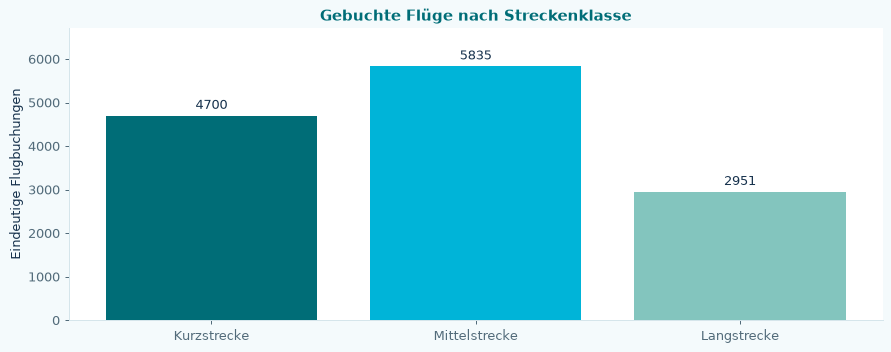

2 Flugbuchungen ohne gültige Distanz sind in den drei Balken nicht enthalten. Streckenanteile erlauben die Unterscheidung gemischter Reisemuster bei gleichem Durchschnitt.

In [ ]:
route_rows = geo[["user_id", "trip_id", "distance_km"]].copy()
route_rows["distance_km"] = pd.to_numeric(route_rows["distance_km"], errors="coerce")
route_rows["distance_km"] = route_rows["distance_km"].where(lambda x: np.isfinite(x) & x.ge(0))
route_rows["distance_band"] = pd.cut(route_rows["distance_km"], bins=[0,1500,3500,np.inf], labels=["short","medium","long"], right=False)
route_counts = pd.crosstab(route_rows["user_id"], route_rows["distance_band"], dropna=False).reindex(columns=["short","medium","long"], fill_value=0)
route_features = pd.DataFrame(index=user_features.index)
route_features["known_distance_flight_count"] = route_rows.groupby("user_id")["distance_km"].count().reindex(user_features.index, fill_value=0)
for band in ["short","medium","long"]:
    route_features[f"{band}_haul_count"] = route_counts[band].reindex(user_features.index, fill_value=0)
    route_features[f"{band}_haul_share"] = safe_ratio(route_features[f"{band}_haul_count"], route_features["known_distance_flight_count"])
    count_columns.append(f"{band}_haul_count")
    rate_columns.append(f"{band}_haul_share")
route_features["unknown_distance_flight_count"] = user_features["booked_flight_count"].fillna(0) - route_features["known_distance_flight_count"]
count_columns += ["known_distance_flight_count", "unknown_distance_flight_count"]
attach(route_features)
assert route_features["unknown_distance_flight_count"].ge(0).all()
assert np.allclose(route_features.loc[route_features["known_distance_flight_count"].gt(0), ["short_haul_share","medium_haul_share","long_haul_share"]].sum(axis=1), 1)
route_totals = route_features[["short_haul_count","medium_haul_count","long_haul_count"]].sum().rename(index={"short_haul_count":"Kurzstrecke","medium_haul_count":"Mittelstrecke","long_haul_count":"Langstrecke"})
eda.display_table(route_features.head(10), title="Streckenmuster je Nutzer", card_width=WIDTH)
fig, ax = plt.subplots(figsize=(10,4))
bars = ax.bar(route_totals.index, route_totals.values, color=THEME["chart_colors"][:3])
ax.bar_label(bars, padding=3); ax.margins(y=.15)
ax.set(title="Gebuchte Flüge nach Streckenklasse", ylabel="Eindeutige Flugbuchungen")
finish_plot(fig)
show_note(f"{int(route_features['unknown_distance_flight_count'].sum()):,} Flugbuchungen ohne gültige Distanz sind in den drei Balken nicht enthalten. Streckenanteile erlauben die Unterscheidung gemischter Reisemuster bei gleichem Durchschnitt.")

## 5. Gepäck, Stornos, Rabatte und Preise
### 5.1. Beobachtete Stornos
Gepäck- und Preismerkmale wurden bereits in Abschnitt 4 einmal aggregiert. Stornos zählen
hier pro gebuchter Reise höchstens einmal, ab der ersten beobachteten Buchung. Teilstornos
und spätere Wiederbuchungen erlauben keine sichere endgültige Stornobilanz.


In [ ]:
storno=trips.groupby("user_id")["cancelled_after_booking"].sum().rename("cancelled_booked_trip_count").to_frame()
unmatched=trips.loc[trips["observed_cancellation"] & ~trips["observed_booking"]].groupby("user_id")["trip_id"].nunique()
storno["cancellation_without_booking_trip_count"]=unmatched.reindex(storno.index,fill_value=0)
storno["observed_cancellation_rate"]=safe_ratio(storno["cancelled_booked_trip_count"],user_features["booked_trip_count"].reindex(storno.index))
attach(storno)
count_columns += ["cancelled_booked_trip_count","cancellation_without_booking_trip_count"]
rate_columns.append("observed_cancellation_rate")
quality("Stornosessions ohne trip_id",(fs["cancellation"].fillna(False) & fs["trip_id"].isna()).sum(),"Nicht zuordenbar")
quality("Storno-Reisen ohne beobachtete Buchung",(trips["observed_cancellation"] & ~trips["observed_booking"]).sum(),"Nicht im Quotenzähler")
quality("Stornos ausschließlich vor erster Buchung",(trips["observed_booking"] & trips["observed_cancellation"] & trips["last_cancellation"].lt(trips["first_booking"])).sum(),"Nicht als nachgelagert gezählt")
preview_block("Beobachtete Stornos",list(storno.columns))


,cancelled_booked_trip_count,cancellation_without_booking_trip_count,observed_cancellation_rate
user_id,,,
94883,0,0.000000,0.000000
101486,0,0.000000,0.000000
101961,0,0.000000,0.000000
106907,0,0.000000,0.000000
118043,0,0.000000,0.000000
149058,0,0.000000,0.000000
153982,0,0.000000,0.000000
167852,-,-,-
174997,1,0.000000,0.333333


### 5.2. Rabattverhalten
Angebotsquote und Rabatthöhe verwenden alle zuordenbaren Sessions. Buchungssessions
mit unbekanntem Rabattflag gelten nicht als rabattlos. Die Angebotsgruppen können sich
in Reisezielen oder anderen Merkmalen unterscheiden: keine kausale Preissensibilität behaupten.
Jeder Quotennenner wird als Beobachtungszahl mitgegeben.


In [ ]:
for kind in ["flight","hotel"]:
    offered=fs[f"{kind}_discount"];booked=fs[f"{kind}_booked"]
    raw=pd.to_numeric(fs[f"{kind}_discount_amount"],errors="coerce")
    valid=raw.between(0,1)
    r=pd.DataFrame({"user_id":fs["user_id"],"offered":offered,"booked":booked,
        "offered_discount_pct":raw.where(valid & offered.fillna(False))*100})
    block=r.groupby("user_id").agg(
        known_offer_count=("offered","count"),offer_count=("offered",lambda x:int(x.fillna(False).sum())),
        mean_offered_discount_pct=("offered_discount_pct","mean"),valid_offered_discount_count=("offered_discount_pct","count"))
    block["discount_offer_rate"]=safe_ratio(block["offer_count"],block["known_offer_count"])
    for value,label in [(True,"with_offer"),(False,"without_offer")]:
        sub=r.loc[r["offered"].eq(value).fillna(False)]
        denom=sub.groupby("user_id")["booked"].count().reindex(block.index,fill_value=0)
        num=sub.groupby("user_id")["booked"].sum().reindex(block.index,fill_value=0)
        block[f"booking_observations_{label}"]=denom
        block[f"booking_rate_{label}"]=safe_ratio(num,denom)
    booked_known=r.loc[r["booked"].fillna(False)]
    denom=booked_known.groupby("user_id")["offered"].count().reindex(block.index,fill_value=0)
    num=booked_known.groupby("user_id")["offered"].sum().reindex(block.index,fill_value=0)
    block["booked_sessions_known_offer_count"]=denom
    block["discounted_booking_share"]=safe_ratio(num,denom)
    block=block.add_prefix(f"{kind}_")
    attach(block)
    count_columns += [c for c in block if c.endswith("_count") or "booking_observations_" in c]
    rate_columns += [c for c in block if c.endswith("_rate") or "_booking_rate_" in c or c.endswith("_share")]
    quality(f"{kind}: Angebot ohne gültigen Betrag",(offered.fillna(False) & ~valid).sum(),"Nicht als 0-Rabatt verwenden")
    quality(f"{kind}: Betrag ohne Angebot",(offered.eq(False).fillna(False) & raw.notna()).sum(),"Separater Widerspruch")
    quality(f"{kind}: Betrag außerhalb 0-1",(raw.notna() & ~valid).sum(),"Aus Rabatthöhe ausgeschlossen")
    preview_block(f"{kind}: Rabattkennzahlen",list(block.columns))


,flight_known_offer_count,flight_offer_count,flight_mean_offered_discount_pct,flight_valid_offered_discount_count,flight_discount_offer_rate,flight_booking_observations_with_offer,flight_booking_rate_with_offer,flight_booking_observations_without_offer,flight_booking_rate_without_offer,flight_booked_sessions_known_offer_count,flight_discounted_booking_share
user_id,,,,,,,,,,,
94883,8,0,-,0,0.000000,0,-,8,0.250000,2,0.000000
101486,7,2,7.500000,2,0.285714,2,0.000000,5,0.200000,1,0.000000
101961,8,2,15.000000,2,0.250000,2,0.500000,6,0.666667,5,0.200000
106907,7,0,-,0,0.000000,0,-,7,0.142857,1,0.000000
118043,8,2,20.000000,2,0.250000,2,0.000000,6,0.500000,3,0.000000
149058,8,1,5.000000,1,0.125000,1,1.000000,7,0.571429,5,0.200000
153982,7,0,-,0,0.000000,0,-,7,0.285714,2,0.000000
167852,8,1,10.000000,1,0.125000,1,0.000000,7,0.000000,0,-
174997,8,1,-,0,0.125000,1,1.000000,7,0.285714,3,0.333333


,hotel_known_offer_count,hotel_offer_count,hotel_mean_offered_discount_pct,hotel_valid_offered_discount_count,hotel_discount_offer_rate,hotel_booking_observations_with_offer,hotel_booking_rate_with_offer,hotel_booking_observations_without_offer,hotel_booking_rate_without_offer,hotel_booked_sessions_known_offer_count,hotel_discounted_booking_share
user_id,,,,,,,,,,,
94883,8,1,10.000000,1,0.125000,1,0.000000,7,0.285714,2,0.000000
101486,7,0,-,0,0.000000,0,-,7,0.285714,2,0.000000
101961,8,1,10.000000,1,0.125000,1,0.000000,7,0.714286,5,0.000000
106907,7,0,-,0,0.000000,0,-,7,0.142857,1,0.000000
118043,8,3,11.666667,3,0.375000,3,0.666667,5,0.400000,4,0.500000
149058,8,0,-,0,0.000000,0,-,8,0.625000,5,0.000000
153982,7,1,15.000000,1,0.142857,1,0.000000,6,0.333333,2,0.000000
167852,8,2,10.000000,2,0.250000,2,0.000000,6,0.000000,0,-
174997,8,3,12.500000,2,0.375000,3,0.333333,5,0.400000,3,0.333333


## 6. Feature-Prüfung und Diagramme
### 6.1. Vollständigkeit, Wertebereiche und Bezugsgrößen
Die Nutzerkohorte bleibt vollständig erhalten. Zähler können 0 sein. Fachlich nicht definierte
Quoten, Mittelwerte oder häufigste Werte bleiben fehlend und werden nicht imputiert.


In [ ]:
for column in count_columns:
    user_features[column]=user_features[column].fillna(0).astype("Int64")
for column in ["preferred_booking_weekday_utc","preferred_booking_hour_utc"]:
    user_features[column]=user_features[column].astype("Int64")
user_features=user_features.sort_index()
assert user_features.index.is_unique and user_features.index.notna().all()
assert set(user_features.index)==set(users_analysis["user_id"])
assert len(user_features)==len(users_analysis)
assert user_features.columns.is_unique
for column in rate_columns:
    assert user_features[column].dropna().between(0,1).all(),column
numeric=user_features.select_dtypes(include="number")
assert not np.isinf(numeric.to_numpy(dtype=float,na_value=np.nan)).any()
assert user_features["cancelled_booked_trip_count"].le(user_features["booked_trip_count"]).all()
assert user_features["session_count"].sum()==len(fs)
assert user_features["booked_trip_count"].sum()==int(trips["observed_booking"].sum())
combo=user_features[["flight_only_booking_share","hotel_only_booking_share","both_booking_share"]]
assert np.allclose(combo.loc[user_features["known_combination_booking_count"].gt(0)].sum(axis=1),1)
feature_quality=pd.DataFrame({"Datentyp":user_features.dtypes.astype(str),"Fehlend":user_features.isna().sum(),"Fehlend (%)":user_features.isna().mean()*100})
quality_report=pd.DataFrame(quality_records)
eda.display_table(feature_quality,title="Vollständigkeit der Nutzerfeatures",card_width=WIDTH,max_height=450)
eda.display_table(quality_report,title="Qualitätsbefunde",card_width=WIDTH,max_height=450)
show_note(f"Geprüft: {len(user_features):,} Nutzer · {len(user_features.columns)} Merkmale · keine unendlichen Zahlen oder Quoten außerhalb 0-1.")


,Datentyp,Fehlend,Fehlend (%)
age_years,int64,0,0.00
age_group,category,0,0.00
married,boolean,0,0.00
has_children,boolean,0,0.00
home_country,str,0,0.00
gender,str,0,0.00
customer_tenure_days,int64,0,0.00
session_count,Int64,0,0.00
known_booking_session_count,Int64,0,0.00
booked_session_count,Int64,0,0.00


,Prüfung,Anzahl,Behandlung
0,Sessions.session_start: ungültige Datumswerte,0,Bleiben fehlend
1,Sessions.session_end: ungültige Datumswerte,0,Bleiben fehlend
2,Flights.departure_time: ungültige Datumswerte,0,Bleiben fehlend
3,Flights.return_time: ungültige Datumswerte,0,Bleiben fehlend
4,Hotels.check_in_time: ungültige Datumswerte,0,Bleiben fehlend
5,Hotels.check_out_time: ungültige Datumswerte,0,Bleiben fehlend
6,Users.birthdate: ungültige Datumswerte,0,Bleiben fehlend
7,Users.sign_up_date: ungültige Datumswerte,0,Bleiben fehlend
8,Users.first_trip_date: ungültige Datumswerte,0,Bleiben fehlend
9,Users.last_trip_date: ungültige Datumswerte,0,Bleiben fehlend


Geprüft: 5,998 Nutzer · 78 Merkmale · keine unendlichen Zahlen oder Quoten außerhalb 0-1.

### 6.2. Feature-Verteilungen
Alle gültigen Werte werden dargestellt; wenige Beobachtungen können zu instabilen Nutzerquoten
führen. Deshalb werden die zugehörigen Beobachtungszahlen nicht verworfen.


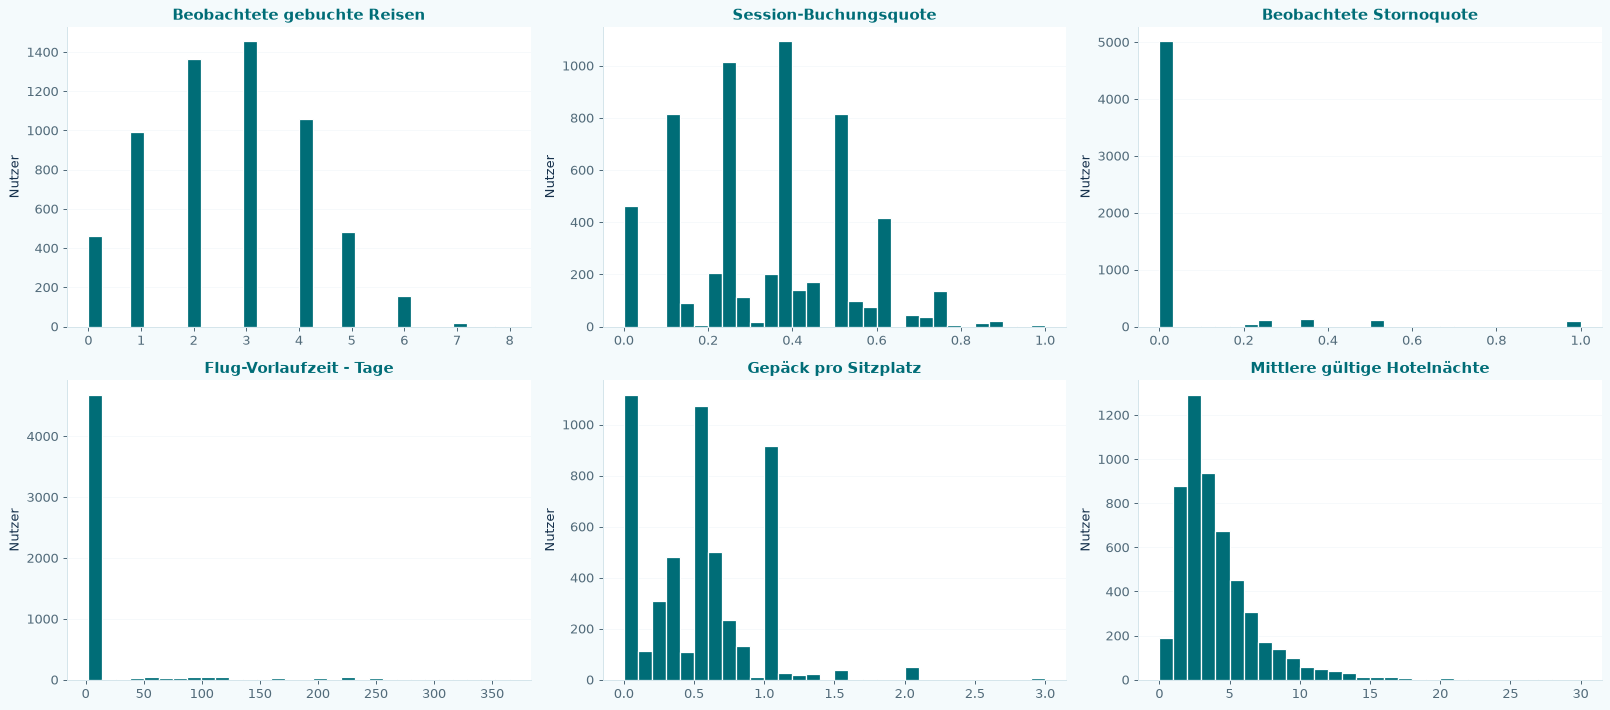

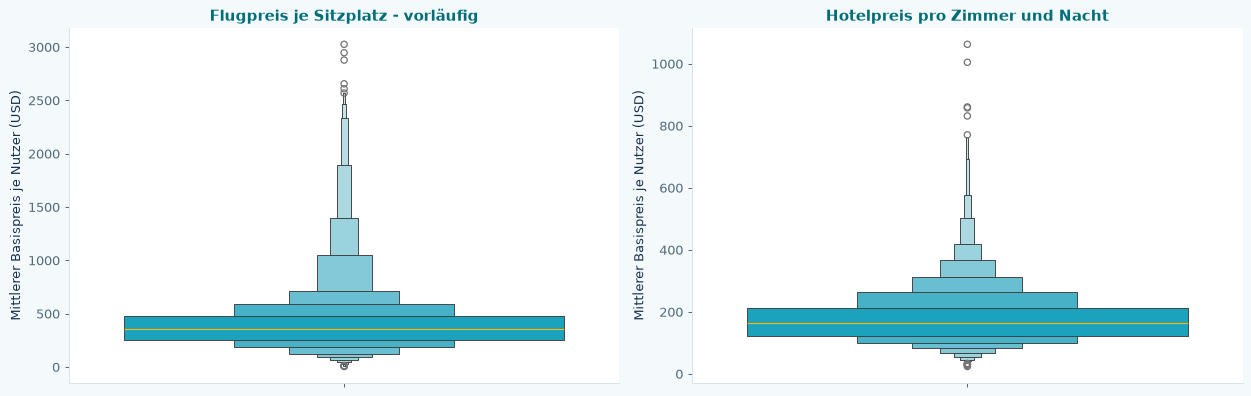

Keine Perk-Zuweisungen oder zusammengesetzten Scores. Verteilungen sind beschreibend, keine kausalen Zusammenhänge.

In [ ]:
fig,axes=plt.subplots(2,3,figsize=(18,8))
for ax,column,title in [
    (axes[0,0],"booked_trip_count","Beobachtete gebuchte Reisen"),(axes[0,1],"booking_rate","Session-Buchungsquote"),
    (axes[0,2],"observed_cancellation_rate","Beobachtete Stornoquote"),(axes[1,0],"mean_flight_lead_days","Flug-Vorlaufzeit - Tage"),
    (axes[1,1],"mean_bags_per_seat","Gepäck pro Sitzplatz"),(axes[1,2],"mean_hotel_nights","Mittlere gültige Hotelnächte")]:
    values=pd.to_numeric(user_features[column],errors="coerce").dropna()
    if len(values):ax.hist(values,bins=30,color=THEME["primary"],edgecolor=THEME["surface"])
    else:ax.text(.5,.5,"Keine gültigen Werte",transform=ax.transAxes,ha="center")
    ax.set_title(title);ax.set_ylabel("Nutzer");ax.grid(axis="y",alpha=.2);ax.set_axisbelow(True)
finish_plot(fig)
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax,column,title in [(axes[0],"mean_fare_per_seat_usd","Flugpreis je Sitzplatz - vorläufig"),(axes[1],"mean_hotel_per_room_night_usd","Hotelpreis pro Zimmer und Nacht")]:
    values=user_features[[column]].dropna()
    if len(values):sns.boxenplot(data=values,y=column,color=THEME["secondary"],line_kws={"color":THEME["accent"]},ax=ax)
    ax.set_title(title);ax.set_ylabel("Mittlerer Basispreis je Nutzer (USD)")
finish_plot(fig)
show_note("Keine Perk-Zuweisungen oder zusammengesetzten Scores. Verteilungen sind beschreibend, keine kausalen Zusammenhänge.")


### 6.3. Familienstand und Kinder gemeinsam betrachten
Die Kreuztabelle zeigt Nutzerzahlen, zusätzlich werden Zeilenprozente ausgegeben.
Unbekannte Angaben bleiben sichtbar. Familienstand und Kinder sind Beschreibungsmerkmale,
keine Beweise für gemeinsame Familienreisen oder einen bevorzugten Vorteil.

Kinder,Nein,Ja,Unbekannt
Verheiratet,,,
Nein,2482,874,0
Ja,1558,1084,0
Unbekannt,0,0,0


Kinder,Nein,Ja,Unbekannt
Verheiratet,,,
Nein,74.000000,26.000000,0.000000
Ja,59.000000,41.000000,0.000000
Unbekannt,-,-,-


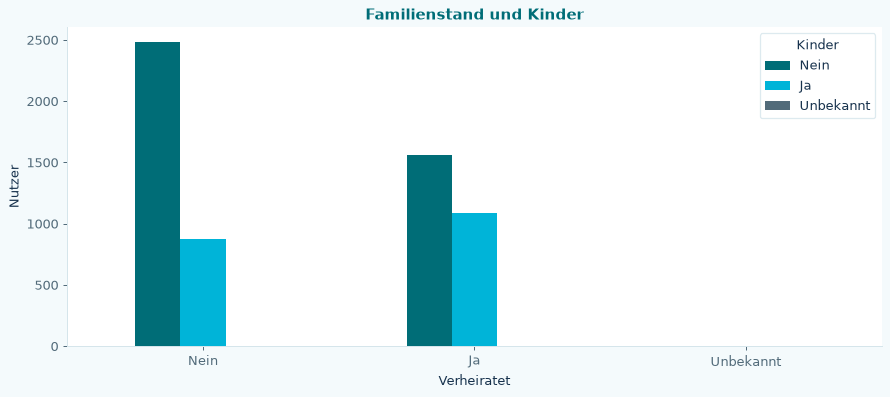

Größte Kombination: verheiratet=Nein, Kinder=Nein (2,482 Nutzer). Absolute Größen hängen von der Kohortenzusammensetzung ab; sie belegen keine Perk-Präferenz.

In [ ]:
family_plot = users_analysis[["user_id","married","has_children"]].copy()
for col in ["married","has_children"]:
    family_plot[col] = as_bool(family_plot[col]).map({True:"Ja",False:"Nein"}).astype("string").fillna("Unbekannt")
family_counts = pd.crosstab(family_plot["married"], family_plot["has_children"]).reindex(index=["Nein","Ja","Unbekannt"],columns=["Nein","Ja","Unbekannt"],fill_value=0)
family_counts.index.name = "Verheiratet"; family_counts.columns.name = "Kinder"
family_percent = family_counts.div(family_counts.sum(axis=1).replace(0,np.nan),axis=0)*100
eda.display_table(family_counts,title="Familienstand × Kinder: Nutzerzahlen",card_width=WIDTH)
eda.display_table(family_percent.round(1),title="Kinderstatus innerhalb des Familienstands (%)",card_width=WIDTH)
fig, ax = plt.subplots(figsize=(10,4.5))
family_counts.plot.bar(ax=ax,color=[THEME["primary"],THEME["secondary"],THEME["text_muted"]],rot=0)
ax.set(title="Familienstand und Kinder",xlabel="Verheiratet",ylabel="Nutzer"); ax.legend(title="Kinder")
finish_plot(fig)
largest_family = family_counts.stack().idxmax()
show_note(f"Größte Kombination: verheiratet={largest_family[0]}, Kinder={largest_family[1]} ({int(family_counts.loc[largest_family]):,} Nutzer). Absolute Größen hängen von der Kohortenzusammensetzung ab; sie belegen keine Perk-Präferenz.")

## 7. Export und Übergabe
Der Ausgabeordner stammt aus der vorhandenen `config.py`. Exportiert werden Featuretabelle,
Qualitätsbefunde, technisches Schema und UTC-Buchungsereignisse zur Nachvollziehbarkeit.
Die fünf vorbereiteten Eingabedateien werden nicht überschrieben.

**Offene Definitionen:** Flug-Gesamtpreisinterpretation bleibt vorläufig. Teilstornos und
Wiederbuchungen sind keine sichere finale Stornobilanz. Preis- und Flughafenreferenzdaten
besitzen keine historische Versionierung. Regionentaxonomie ist nicht festgelegt.


In [ ]:
FEATURES_FOLDER=config.DATA_FEATURES_FOLDER/"working_cutoff_20230716"
FEATURES_FOLDER.mkdir(parents=True,exist_ok=True)
user_features.reset_index().to_csv(FEATURES_FOLDER/"user_features.csv",index=False)
quality_report.to_csv(FEATURES_FOLDER/"feature_quality.csv",index=False)
feature_quality.rename_axis("feature").reset_index().to_csv(FEATURES_FOLDER/"feature_schema.csv",index=False)
booking_events[["user_id","session_id","trip_id","session_start","booking_weekday_utc","booking_hour_utc"]].to_csv(FEATURES_FOLDER/"booking_events_utc.csv",index=False)
show_note(f"Features gespeichert: {len(user_features):,} Nutzer · {user_features.shape[1]} Merkmale · {FEATURES_FOLDER/'user_features.csv'}")


Features gespeichert: 5,998 Nutzer · 78 Merkmale · outputs\release_feature_test\working_cutoff_20230716\user_features.csv

## 8. Hypothesen, Feature-Auswahl und K-Means
### 8.1. Hypothesen zu fünf Vorteilen
K-Means bildet Verhaltensgruppen, keine bewiesenen Präferenzen. Die anschließende
Perk-Zuordnung ist ein explizites, vorläufiges Regelmodell. Mehrere Cluster dürfen denselben
Vorteil erhalten; fünf Vorteile erzwingen weder fünf Cluster noch gleiche Gruppengrößen.

| Vorteil | Hypothese und Kennzahlen | Grenzen |
|---|---|---|
| Kostenlose Stornierung | Wiederholte beobachtete Stornos sprechen für Flexibilitätsbedarf; Stornoquote und Zahl beobachteter Reisen | Wenige Reisen machen Quoten instabil; Teilstornos/Wiederbuchungen nicht sicher auflösbar |
| Kostenloses Gepäck | Regelmäßige Gepäckbuchungen sprechen für Gepäckbedarf; Gepäckanteil und Gepäck je Sitzplatz | Ausbleibende Gepäckbuchung beweist keinen fehlenden Bedarf |
| Kostenlose Mahlzeiten | Lange Flugstrecken sind ein indirekter Hinweis; Langstreckenanteil | Keine Mahlzeiten- oder Verpflegungsdaten; schwächste Hypothese |
| Erste Hotelnacht kostenlos | Hotelbuchungsanteil und kurze Aufenthalte können für hohen relativen Nutzen sprechen | Eine kostenlose Nacht deckt bei n Nächten ungefähr 1/n der gleich teuren Nächte; kein Zahlungsbereitschaftsnachweis |
| Exklusive Rabatte | Hoher Anteil rabattierter Buchungssessions kann Rabattnähe anzeigen; getrennte Flug-/Hotelquoten | Angebote sind nicht zufällig; kein kausaler Nachweis von Preissensibilität |

### 8.2. Begründete Auswahl und fehlende Werte
Verhalten bildet die Cluster; Alter, Geschlecht, Familienstand und Kinder dienen nur zur
nachträglichen Beschreibung. IDs, Modi von Uhrzeit/Wochentag, Lieblingsorte und technische
Beobachtungszähler werden nicht als numerische Abstände verwendet.
Eine Buchungssumme wird logarithmiert, damit Vielbucher nicht allein dominieren.
Quoten und Mittelwerte ohne Ereignisse bleiben in `user_features` fehlend. Ausschließlich
für die Modellmatrix erfolgt Median-Imputation. Zwei Verfügbarkeitsindikatoren kennzeichnen
Nutzer ohne Flug bzw. Hotel. Weitere fehlende Werte werden berichtet. Die Imputation
behauptet kein tatsächliches durchschnittliches Verhalten.
Stark korrelierte Kandidaten (|Spearman| > 0,85) werden in dokumentierter Prioritätsreihenfolge
reduziert; konstante und überwiegend fehlende Merkmale werden ausgeschlossen.
Kontinuierliche Werte werden für das Modell bei P1/P99 begrenzt und standardisiert.
Die ursprünglichen Nutzerfeatures werden dabei nicht verändert.

,Feature,Begründung,Fehlend (%),Entscheidung
0,booked_trip_count,Reisehäufigkeit; log1p vor Modellierung,0.00,Verwendet
1,booking_rate,Buchung gegenüber Browsing,0.00,Ausgeschlossen: redundant zu booked_trip_count (rho=0.97)
2,both_booking_share,Kombination Flug und Hotel,7.70,Verwendet
3,mean_bags_per_seat,Gepäckumfang je Sitzplatz,13.85,Verwendet
4,observed_cancellation_rate,Beobachteter Flexibilitätsbedarf,7.70,Verwendet
5,mean_hotel_nights,Typische Aufenthaltsdauer,10.30,Verwendet
6,mean_seats,Typischer Buchungsumfang,13.85,Verwendet
7,long_haul_share,Langstreckenorientierung,13.87,Verwendet
8,flight_discounted_booking_share,Rabattnähe Flug,13.64,Verwendet
9,hotel_discounted_booking_share,Rabattnähe Hotel,9.34,Verwendet


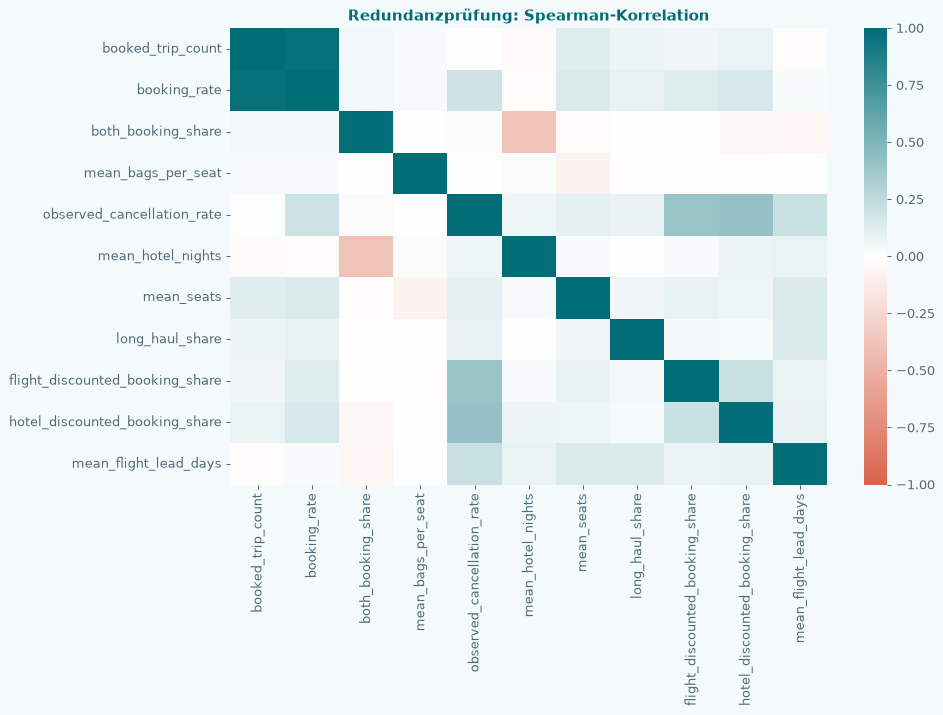

,Feature,Schiefe,P1,P99,Begrenzte Werte
0,booked_trip_count,-0.872689,0.000000,1.945910,25
1,both_booking_share,-0.988461,0.000000,1.000000,0
2,mean_bags_per_seat,0.881827,0.000000,2.000000,8
3,observed_cancellation_rate,4.493228,0.000000,1.000000,0
4,mean_hotel_nights,2.261839,0.000000,15.000000,49
5,mean_seats,4.151452,1.000000,3.000000,25
6,long_haul_share,1.286308,0.000000,1.000000,0
7,flight_discounted_booking_share,1.556712,0.000000,1.000000,0
8,hotel_discounted_booking_share,1.680267,0.000000,1.000000,0
9,mean_flight_lead_days,4.389496,4.340611,252.703250,104


10 Verhaltensmerkmale plus zwei Verfügbarkeitsindikatoren. Median-Imputation kann Gruppen beeinflussen; die nachfolgende Stabilitätsprüfung ist deshalb Teil der Bewertung.

In [ ]:
candidate_reasons = {
    "booked_trip_count":"Reisehäufigkeit; log1p vor Modellierung",
    "booking_rate":"Buchung gegenüber Browsing",
    "both_booking_share":"Kombination Flug und Hotel",
    "mean_bags_per_seat":"Gepäckumfang je Sitzplatz",
    "observed_cancellation_rate":"Beobachteter Flexibilitätsbedarf",
    "mean_hotel_nights":"Typische Aufenthaltsdauer",
    "mean_seats":"Typischer Buchungsumfang",
    "long_haul_share":"Langstreckenorientierung",
    "flight_discounted_booking_share":"Rabattnähe Flug",
    "hotel_discounted_booking_share":"Rabattnähe Hotel",
    "mean_flight_lead_days":"Planungsvorlauf Flug",
}
model_raw = user_features[list(candidate_reasons)].apply(pd.to_numeric,errors="coerce").astype(float)
model_raw["booked_trip_count"] = np.log1p(model_raw["booked_trip_count"])
selection_rows=[]; retained=[]
for col in model_raw:
    missing_share=model_raw[col].isna().mean(); reason="Verwendet"
    if model_raw[col].nunique(dropna=True)<2: reason="Ausgeschlossen: konstant/leer"
    elif missing_share>.70: reason="Ausgeschlossen: mehr als 70 % fehlend"
    else:
        for previous in retained:
            corr=model_raw[[col,previous]].corr(method="spearman").iloc[0,1]
            if pd.notna(corr) and abs(corr)>.85:
                reason=f"Ausgeschlossen: redundant zu {previous} (rho={corr:.2f})"; break
    if reason=="Verwendet": retained.append(col)
    selection_rows.append({"Feature":col,"Begründung":candidate_reasons[col],"Fehlend (%)":missing_share*100,"Entscheidung":reason})
feature_selection=pd.DataFrame(selection_rows)
eda.display_table(feature_selection,title="Feature-Auswahl für K-Means",card_width=WIDTH)
correlations=model_raw.corr(method="spearman")
fig,ax=plt.subplots(figsize=(11,8))
sns.heatmap(correlations,vmin=-1,vmax=1,cmap=THEME_DIVERGING_CMAP,center=0,ax=ax)
ax.set_title("Redundanzprüfung: Spearman-Korrelation"); finish_plot(fig)
outlier_rows=[]; bounds={}
for col in retained:
    lo,hi=model_raw[col].quantile([.01,.99]); bounds[col]=(lo,hi)
    outlier_rows.append({"Feature":col,"Schiefe":model_raw[col].skew(),"P1":lo,"P99":hi,"Begrenzte Werte":int((model_raw[col].lt(lo)|model_raw[col].gt(hi)).sum())})
outlier_report=pd.DataFrame(outlier_rows)
eda.display_table(outlier_report,title="Ausreißerbehandlung: nur Modellmatrix",card_width=WIDTH)
imputer=SimpleImputer(strategy="median")
scaler=StandardScaler()
def prepare_cluster_matrix(lower=.01,upper=.99):
    numeric=model_raw[retained].copy()
    for col in retained:
        lo,hi=numeric[col].quantile([lower,upper]); numeric[col]=numeric[col].clip(lo,hi)
    filled=pd.DataFrame(SimpleImputer(strategy="median").fit_transform(numeric),index=numeric.index,columns=numeric.columns)
    # Verfügbarkeitsindikatoren bleiben 0/1 und werden nicht auf seltene Gruppen hochskaliert.
    scaled=pd.DataFrame(StandardScaler().fit_transform(filled),index=filled.index,columns=filled.columns)
    scaled["no_flight_history"]=user_features["booked_flight_count"].eq(0).astype(float)
    scaled["no_hotel_history"]=user_features["booked_hotel_count"].eq(0).astype(float)
    return scaled
cluster_matrix=prepare_cluster_matrix()
assert np.isfinite(cluster_matrix.to_numpy()).all()
assert cluster_matrix.index.equals(user_features.index)
show_note(f"{len(retained)} Verhaltensmerkmale plus zwei Verfügbarkeitsindikatoren. Median-Imputation kann Gruppen beeinflussen; die nachfolgende Stabilitätsprüfung ist deshalb Teil der Bewertung.")

### 8.3. Priorität 1 - k=2 bis 5 systematisch vergleichen
Alle Lösungen werden auf derselben Modellmatrix und derselben festen Silhouette-Stichprobe
verglichen. Bewertet werden Silhouette, Gruppengrößen, Medianprofile und Stabilität.
Eine große Mehrheit in einem Cluster ist nicht automatisch falsch, kann aber wenig
zusätzliche Differenzierung für das Marketing bieten. Es wird kein k erzwungen, nur um
fünf Vorteile abzubilden. Cluster-Nummern sind zwischen Lösungen nicht vergleichbar.
Andere Startwerte und 80-%-Teilstichproben werden für jedes k untersucht; ARI ist
nummerierungsunabhängig. Ausreißergrenzen werden ebenfalls variiert.
Die Zweierlösung bleibt der technische Referenzpunkt; die Regeln im nächsten Abschnitt
bilden eine unabhängige, verständliche Vergleichslösung. Keine Auswahl nach Silhouette allein.

Für eine feinere explorative Arbeitslösung wird zusätzlich das kleinste k≥3 mit höchstens
80 % Nutzern in der größten Gruppe und ARI-Minimum ≥0,8 betrachtet. Diese Arbeitskriterien
priorisieren Einfachheit, eine gewisse Differenzierung und Robustheit. Sie ersetzen kein
fachliches Urteil. Der technische Referenzpunkt und diese Arbeitslösung werden separat exportiert.


,k,Silhouette,Inertia,Kleinste Gruppe (%),Größte Gruppe (%),ARI Median,ARI Minimum
0,2,0.471000,52469.395000,5.63,94.36,0.992000,0.762000
1,3,0.217000,46045.083000,5.54,73.31,0.988000,0.919000
2,4,0.187000,42154.383000,5.42,67.17,0.967000,0.911000
3,5,0.167000,38860.572000,5.00,47.43,0.833000,0.732000


,k,Prüfung,Variante,ARI
0,2,Startwert,7,1.000000
1,2,Startwert,21,1.000000
2,2,Startwert,99,1.000000
3,2,80-%-Teilstichprobe,0,0.996000
4,2,80-%-Teilstichprobe,1,0.986000
5,2,80-%-Teilstichprobe,2,0.988000
6,2,80-%-Teilstichprobe,3,0.996000
7,2,80-%-Teilstichprobe,4,0.976000
8,2,Ausreißergrenze,P0/P100,0.982000
9,2,Ausreißergrenze,P2.5/P97.5,0.762000


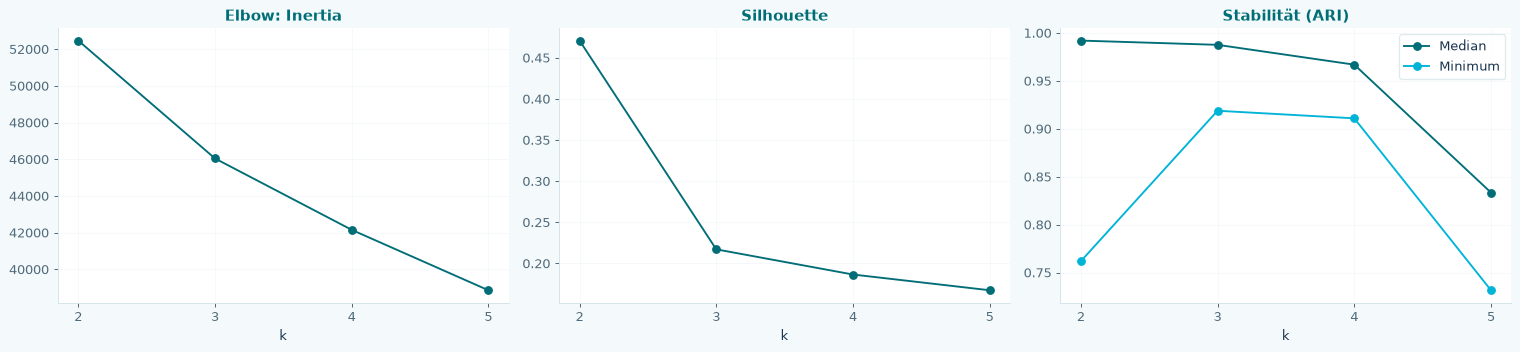

,Nutzer,Anteil (%),booked_trip_count,observed_cancellation_rate,mean_flight_lead_days,mean_hotel_nights,mean_bags_per_seat,long_haul_share,flight_discounted_booking_share,hotel_discounted_booking_share
cluster,,,,,,,,,,
0,338,5.63,2.000000,0.500000,168.297000,6.000000,0.500000,0.500000,0.500000,0.500000
1,5660,94.36,3.000000,0.000000,7.560000,3.000000,0.500000,0.000000,0.000000,0.000000


k=2: größte Gruppe 94.4 %, minimale ARI 0.762. Medianwerte ignorieren fehlende Angaben; die verfügbare Zahl ist zusätzlich im Export enthalten.

,Nutzer,Anteil (%),booked_trip_count,observed_cancellation_rate,mean_flight_lead_days,mean_hotel_nights,mean_bags_per_seat,long_haul_share,flight_discounted_booking_share,hotel_discounted_booking_share
cluster,,,,,,,,,,
0,332,5.54,2.000000,0.500000,168.539000,6.000000,0.500000,0.500000,0.500000,0.500000
1,1269,21.16,1.000000,0.000000,7.500000,7.000000,0.750000,0.000000,0.000000,0.000000
2,4397,73.31,3.000000,0.000000,7.563000,2.714000,0.500000,0.000000,0.000000,0.000000


k=3: größte Gruppe 73.3 %, minimale ARI 0.919. Medianwerte ignorieren fehlende Angaben; die verfügbare Zahl ist zusätzlich im Export enthalten.

,Nutzer,Anteil (%),booked_trip_count,observed_cancellation_rate,mean_flight_lead_days,mean_hotel_nights,mean_bags_per_seat,long_haul_share,flight_discounted_booking_share,hotel_discounted_booking_share
cluster,,,,,,,,,,
0,734,12.24,0.000000,0.000000,7.470000,2.000000,1.000000,0.000000,0.000000,0.000000
1,325,5.42,2.000000,0.500000,168.672000,6.000000,0.500000,0.500000,0.500000,0.500000
2,4029,67.17,3.000000,0.000000,7.576000,2.667000,0.500000,0.000000,0.000000,0.000000
3,910,15.17,2.000000,0.000000,7.423000,7.000000,0.500000,0.000000,0.000000,0.000000


k=4: größte Gruppe 67.2 %, minimale ARI 0.911. Medianwerte ignorieren fehlende Angaben; die verfügbare Zahl ist zusätzlich im Export enthalten.

,Nutzer,Anteil (%),booked_trip_count,observed_cancellation_rate,mean_flight_lead_days,mean_hotel_nights,mean_bags_per_seat,long_haul_share,flight_discounted_booking_share,hotel_discounted_booking_share
cluster,,,,,,,,,,
0,760,12.67,2.000000,0.000000,7.468000,7.000000,0.500000,0.000000,0.000000,0.000000
1,2845,47.43,3.000000,0.000000,7.574000,2.667000,0.500000,0.000000,0.000000,0.000000
2,735,12.25,0.000000,0.000000,7.463000,2.000000,1.000000,0.000000,0.000000,0.000000
3,1358,22.64,3.000000,0.000000,7.585000,3.000000,0.500000,0.000000,0.500000,0.000000
4,300,5.00,2.000000,0.500000,169.148000,6.667000,0.500000,0.500000,0.500000,0.500000


k=5: größte Gruppe 47.4 %, minimale ARI 0.732. Medianwerte ignorieren fehlende Angaben; die verfügbare Zahl ist zusätzlich im Export enthalten.

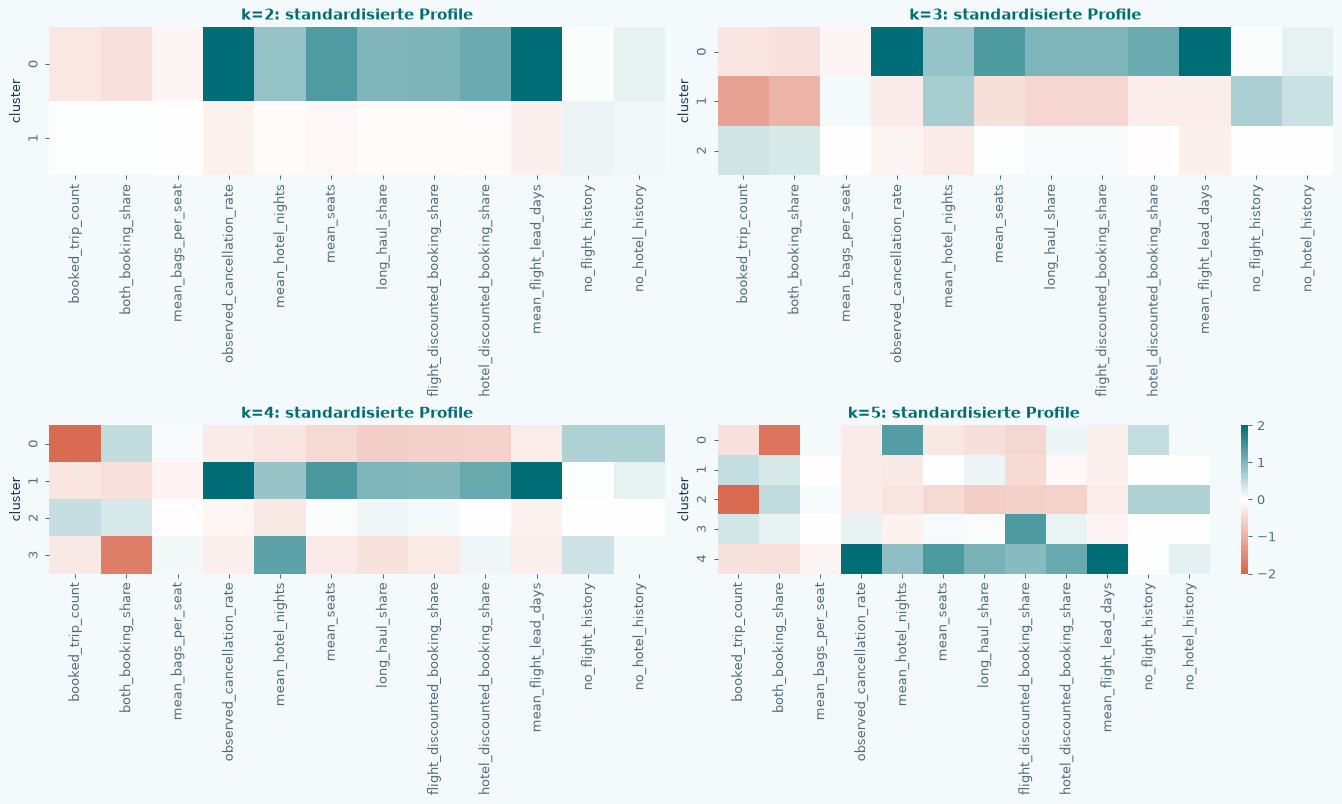

Technischer Referenzpunkt bleibt k=2. Die Silhouette liefert keine fachliche Perk-Präferenz. Regelgruppen werden deshalb separat geprüft; k=3-5 sind dokumentierte Alternativen, keine automatisch besseren Marketinglösungen.

In [ ]:
k_models={}; k_rows=[]; k_stability_rows=[]; k_profiles={}; k_sizes={}
for k in range(2,6):
    model=KMeans(n_clusters=k,n_init=20,random_state=42).fit(cluster_matrix)
    labels=pd.Series(model.labels_,index=user_features.index,name="cluster")
    sizes=labels.value_counts().sort_index()
    profile=user_features[list(candidate_reasons)].join(labels).groupby("cluster").median(numeric_only=True)
    k_models[k]=model; k_profiles[k]=profile; k_sizes[k]=sizes
    for seed in [7,21,99]:
        alt=KMeans(n_clusters=k,n_init=20,random_state=seed).fit_predict(cluster_matrix)
        k_stability_rows.append({"k":k,"Prüfung":"Startwert","Variante":str(seed),"ARI":adjusted_rand_score(labels,alt)})
    for seed in range(5):
        alt=KMeans(n_clusters=k,n_init=20,random_state=seed).fit(cluster_matrix.sample(frac=.8,random_state=seed))
        k_stability_rows.append({"k":k,"Prüfung":"80-%-Teilstichprobe","Variante":str(seed),"ARI":adjusted_rand_score(labels,alt.predict(cluster_matrix))})
    for lo,hi in [(0,1),(.025,.975)]:
        alternative=prepare_cluster_matrix(lo,hi)
        alt=KMeans(n_clusters=k,n_init=20,random_state=42).fit_predict(alternative)
        k_stability_rows.append({"k":k,"Prüfung":"Ausreißergrenze","Variante":f"P{lo*100:g}/P{hi*100:g}","ARI":adjusted_rand_score(labels,alt)})
    tested=pd.DataFrame(k_stability_rows).query("k == @k")["ARI"]
    k_rows.append({"k":k,"Silhouette":silhouette_score(cluster_matrix,labels,sample_size=min(2000,len(labels)),random_state=42),"Inertia":model.inertia_,"Kleinste Gruppe (%)":sizes.min()/len(labels)*100,"Größte Gruppe (%)":sizes.max()/len(labels)*100,"ARI Median":tested.median(),"ARI Minimum":tested.min()})
k_comparison=pd.DataFrame(k_rows); cluster_stability=pd.DataFrame(k_stability_rows)
chosen_k=int(k_comparison.sort_values(["Silhouette","k"],ascending=[False,True]).iloc[0]["k"])
# Feinere explorative Arbeitslösung: kleinstes k>=3 mit größter Gruppe <=80 %
# und ARI-Minimum >=0,8. Dokumentierte Arbeitskriterien, keine allgemeine Gütegarantie.
business_candidates=k_comparison.loc[k_comparison["k"].ge(3)&k_comparison["Größte Gruppe (%)"].le(80)&k_comparison["ARI Minimum"].ge(.8)]
preferred_k=int(business_candidates.sort_values("k").iloc[0]["k"]) if len(business_candidates) else chosen_k
kmeans=k_models[chosen_k]
cluster_labels=pd.Series(kmeans.labels_,index=user_features.index,name="cluster")
eda.display_table(k_comparison.round(3),title="k=2-5: Trennung, Größen und Stabilität",card_width=WIDTH)
eda.display_table(cluster_stability.round(3),title="Alle Stabilitätsprüfungen",card_width=WIDTH,max_height=350)
fig,axes=plt.subplots(1,3,figsize=(17,4))
axes[0].plot(k_comparison["k"],k_comparison["Inertia"],marker="o");axes[0].set(title="Elbow: Inertia",xlabel="k")
axes[1].plot(k_comparison["k"],k_comparison["Silhouette"],marker="o");axes[1].set(title="Silhouette",xlabel="k")
axes[2].plot(k_comparison["k"],k_comparison["ARI Median"],marker="o",label="Median")
axes[2].plot(k_comparison["k"],k_comparison["ARI Minimum"],marker="o",label="Minimum");axes[2].set(title="Stabilität (ARI)",xlabel="k");axes[2].legend()
for ax in axes:ax.set_xticks([2,3,4,5]);ax.grid(alpha=.2)
finish_plot(fig)
profile_columns=["booked_trip_count","observed_cancellation_rate","mean_flight_lead_days","mean_hotel_nights","mean_bags_per_seat","long_haul_share","flight_discounted_booking_share","hotel_discounted_booking_share"]
for k in range(2,6):
    profile=k_profiles[k][profile_columns].copy()
    profile.insert(0,"Nutzer",k_sizes[k]);profile.insert(1,"Anteil (%)",k_sizes[k]/len(user_features)*100)
    eda.display_table(profile.round(3),title=f"k={k}: Originalwerte als Median",card_width=WIDTH)
    show_note(f"k={k}: größte Gruppe {k_comparison.set_index('k').loc[k,'Größte Gruppe (%)']:.1f} %, minimale ARI {k_comparison.set_index('k').loc[k,'ARI Minimum']:.3f}. Medianwerte ignorieren fehlende Angaben; die verfügbare Zahl ist zusätzlich im Export enthalten.")
fig,axes=plt.subplots(2,2,figsize=(15,9))
for k,ax in zip(range(2,6),axes.flat):
    labels=pd.Series(k_models[k].labels_,index=cluster_matrix.index,name="cluster")
    z=cluster_matrix.join(labels).groupby("cluster").mean()
    sns.heatmap(z,cmap=THEME_DIVERGING_CMAP,center=0,vmin=-2,vmax=2,ax=ax,cbar=(k==5));ax.set_title(f"k={k}: standardisierte Profile")
finish_plot(fig)
show_note(f"Technischer Referenzpunkt bleibt k={chosen_k}. Die Silhouette liefert keine fachliche Perk-Präferenz. Regelgruppen werden deshalb separat geprüft; k=3-5 sind dokumentierte Alternativen, keine automatisch besseren Marketinglösungen.")

### 8.4. Priorität 2 - unabhängige regelbasierte Verhaltensgruppen
Regeln verwenden ursprüngliche, nicht imputierte Merkmale. Mindestens drei passende
Beobachtungen sind ein Arbeitskriterium, keine statistische Garantie.

| Muster | Transparente Arbeitsregel |
|---|---|
| Flexibilität | mindestens 3 gebuchte Reisen und beobachtete Stornoquote ≥ 30 % |
| Gepäck | mindestens 3 bekannte Flugbuchungen und Gepäckanteil ≥ 50 % |
| Hotelorientierung | mindestens 3 Hotelbuchungen und keine beobachtete Flugbuchung |
| Flugorientierung | mindestens 3 Flugbuchungen und keine beobachtete Hotelbuchung |

Mehrfachtreffer bleiben als „Mehrere ausgeprägte Muster“ sichtbar. Niemand überschreibt
unbemerkt eine frühere Regel. Nutzer ohne Buchung, mit weniger als drei Reisen und ohne
ausgeprägtes Muster werden getrennt ausgewiesen. Diese Gruppen beschreiben Verhalten,
sie sind noch keine Perks. Demografie wird nur beschreibend verwendet.
Die Schwellen werden um ±20 % sowie mit Mindestzahlen 2/5 variiert.

,Nutzer,Anteil (%)
rule_segment,,
Wenig Beobachtungen,2361,39.36
Gemischtes Reiseverhalten,1586,26.44
Gepäck,1433,23.89
Keine beobachtete Buchung,462,7.70
Flexibilität,79,1.32
Mehrere ausgeprägte Muster,70,1.17
Hotelorientierung,7,0.12


,booked_trip_count,observed_cancellation_rate,mean_flight_lead_days,mean_hotel_nights,mean_bags_per_seat,long_haul_share,flight_discounted_booking_share,hotel_discounted_booking_share
rule_segment,,,,,,,,
Flexibilität,3.000000,0.333000,8.654000,3.333000,0.333000,0.333000,0.333000,0.333000
Gemischtes Reiseverhalten,3.000000,0.000000,7.587000,3.333000,0.333000,0.000000,0.000000,0.000000
Gepäck,4.000000,0.000000,7.609000,2.750000,0.667000,0.200000,0.000000,0.000000
Hotelorientierung,3.000000,0.000000,-,9.333000,-,-,-,0.333000
Keine beobachtete Buchung,0.000000,-,-,-,-,-,-,-
Mehrere ausgeprägte Muster,3.000000,0.333000,8.782000,3.000000,0.667000,0.333000,0.250000,0.333000
Wenig Beobachtungen,2.000000,0.000000,7.717000,3.000000,0.500000,0.000000,0.000000,0.000000


,Flexibilität,Gepäck,Hotelorientierung,Flugorientierung
Flexibilität,149,68,2,0
Gepäck,68,1501,0,0
Hotelorientierung,2,0,9,0
Flugorientierung,0,0,0,0


,Variante,Geändert (%),ARI
0,Mindestens 2,29.11,0.362000
1,Mindestens 5,44.40,0.173000
2,Schwellen −20 %,3.63,0.937000
3,Schwellen +20 %,8.04,0.850000


cluster,0,1
rule_segment,,
Flexibilität,33,46
Gemischtes Reiseverhalten,28,1558
Gepäck,9,1424
Hotelorientierung,0,7
Keine beobachtete Buchung,0,462
Mehrere ausgeprägte Muster,26,44
Wenig Beobachtungen,242,2119


cluster,0,1,2
rule_segment,,,
Flexibilität,31,1,47
Gemischtes Reiseverhalten,28,101,1457
Gepäck,9,6,1418
Hotelorientierung,0,7,0
Keine beobachtete Buchung,0,462,0
Mehrere ausgeprägte Muster,25,0,45
Wenig Beobachtungen,239,692,1430


cluster,0,1,2,3
rule_segment,,,,
Flexibilität,0,31,45,3
Gemischtes Reiseverhalten,0,28,1353,205
Gepäck,0,6,1386,41
Hotelorientierung,0,0,0,7
Keine beobachtete Buchung,462,0,0,0
Mehrere ausgeprägte Muster,0,25,42,3
Wenig Beobachtungen,272,235,1203,651


cluster,0,1,2,3,4
rule_segment,,,,,
Flexibilität,1,0,0,52,26
Gemischtes Reiseverhalten,148,983,0,431,24
Gepäck,20,1017,0,391,5
Hotelorientierung,7,0,0,0,0
Keine beobachtete Buchung,0,0,462,0,0
Mehrere ausgeprägte Muster,0,0,0,49,21
Wenig Beobachtungen,584,845,273,435,224


,k,ARI zu Regeln
0,2,-0.003000
1,3,0.091000
2,4,0.102000
3,5,0.098000


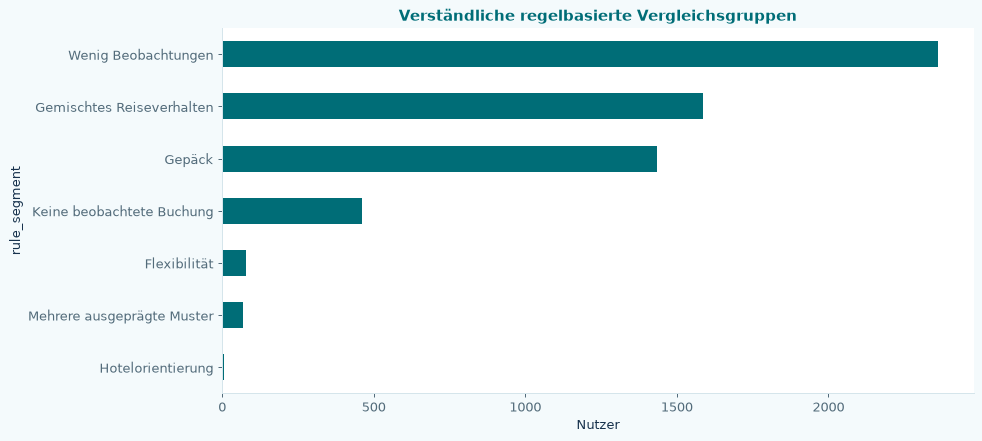

Regeln sind die erklärte fachliche Baseline, K-Means ist eine ergänzende Suche nach Mustern. Niedrige Übereinstimmung bedeutet unterschiedliche Gruppierungslogiken, nicht automatisch eine schlechtere Methode. Keine der beiden Lösungen ist eine bekannte Wahrheit.

In [ ]:
def make_rule_segments(minimum=3,cancel_threshold=.3,baggage_threshold=.5):
    u=user_features
    flags=pd.DataFrame(index=u.index)
    flags["Flexibilität"]=u["booked_trip_count"].ge(minimum)&u["observed_cancellation_rate"].ge(cancel_threshold)
    flags["Gepäck"]=u["known_baggage_booking_count"].ge(minimum)&u["checked_bags_booking_rate"].ge(baggage_threshold)
    flags["Hotelorientierung"]=u["booked_hotel_count"].ge(minimum)&u["booked_flight_count"].eq(0)
    flags["Flugorientierung"]=u["booked_flight_count"].ge(minimum)&u["booked_hotel_count"].eq(0)
    flags=flags.fillna(False)
    number=flags.sum(axis=1)
    group=pd.Series("Gemischtes Reiseverhalten",index=u.index,name="rule_segment")
    for label in flags:group.loc[number.eq(1)&flags[label]]=label
    group.loc[number.gt(1)]="Mehrere ausgeprägte Muster"
    group.loc[u["booked_trip_count"].lt(minimum)&number.eq(0)]="Wenig Beobachtungen"
    group.loc[u["booked_trip_count"].eq(0)]="Keine beobachtete Buchung"
    return group,flags
rule_segments,rule_flags=make_rule_segments()
rule_sizes=rule_segments.value_counts().rename("Nutzer").to_frame();rule_sizes["Anteil (%)"]=rule_sizes["Nutzer"]/len(user_features)*100
rule_profile=user_features[profile_columns].join(rule_segments).groupby("rule_segment").median(numeric_only=True)
eda.display_table(rule_sizes,title="Regelgruppen: vollständige Abdeckung",card_width=WIDTH)
eda.display_table(rule_profile.round(3),title="Regelgruppen: Originalprofile",card_width=WIDTH)
eda.display_table(rule_flags.T.astype(int).dot(rule_flags.astype(int)),title="Überschneidungen der Verhaltensmuster",card_width=WIDTH)
rule_stability=[]
for minimum,ct,bt,label in [(2,.3,.5,"Mindestens 2"),(5,.3,.5,"Mindestens 5"),(3,.24,.4,"Schwellen −20 %"),(3,.36,.6,"Schwellen +20 %")]:
    alt,_=make_rule_segments(minimum,ct,bt)
    rule_stability.append({"Variante":label,"Geändert (%)":alt.ne(rule_segments).mean()*100,"ARI":adjusted_rand_score(rule_segments,alt)})
rule_stability=pd.DataFrame(rule_stability)
eda.display_table(rule_stability.round(3),title="Empfindlichkeit der Regelgruppen",card_width=WIDTH)
rule_k_comparison=[]; rule_cluster_tables={}
for k in range(2,6):
    labels=pd.Series(k_models[k].labels_,index=user_features.index,name="cluster")
    cross=pd.crosstab(rule_segments,labels)
    rule_cluster_tables[k]=cross
    rule_k_comparison.append({"k":k,"ARI zu Regeln":adjusted_rand_score(rule_segments,labels)})
    eda.display_table(cross,title=f"Regelgruppen × K-Means k={k}",card_width=WIDTH)
rule_k_comparison=pd.DataFrame(rule_k_comparison)
eda.display_table(rule_k_comparison.round(3),title="Übereinstimmung der Methoden (keine Accuracy)",card_width=WIDTH)
fig,ax=plt.subplots(figsize=(11,5));rule_sizes["Nutzer"].sort_values().plot.barh(ax=ax,color=THEME["primary"])
ax.set(title="Verständliche regelbasierte Vergleichsgruppen",xlabel="Nutzer");finish_plot(fig)
show_note("Regeln sind die erklärte fachliche Baseline, K-Means ist eine ergänzende Suche nach Mustern. Niedrige Übereinstimmung bedeutet unterschiedliche Gruppierungslogiken, nicht automatisch eine schlechtere Methode. Keine der beiden Lösungen ist eine bekannte Wahrheit.")

### 8.5. Priorität 3 - Perk-Logik ohne Hotel-Bonus überarbeiten
Die bisherige Hotel-Basis von 0,6 wird entfernt. Ein hoher Hotelpreis allein begründet keine
Präferenz. Mahlzeiten werden wegen fehlender direkter Verpflegungsdaten **nicht automatisch
empfohlen**; Langstrecken bleiben ein gekennzeichneter Proxy für einen späteren Test.

Vier Vorschlagsindikatoren werden unabhängig von Cluster und Demografie berechnet:

| Vorteil | Neue Arbeitsdefinition |
|---|---|
| Stornierung | konservativ abgeschwächte beobachtete Stornoquote bei gebuchten Reisen |
| Gepäck | konservativ abgeschwächter Anteil eindeutiger Flugbuchungen mit Gepäck |
| Rabatte | konservativ abgeschwächter Anteil eindeutiger gebuchter Komponenten mit Rabattangebot |
| Erste Hotelnacht | Hotelanteil an gebuchten Reisen × mittlerer relativer Nutzen einer Nacht × n/(n+3) |

Für Hotelaufenthalte ist relativer Nutzen = 1/Nächte (nur Nächte ≥ 1); Rabattmerkmale nutzen
die bereits ausgewählte letzte nicht als Storno markierte Buchung je Komponente. Flug und
Hotel derselben Reise sind zwei Komponenten und werden im Rabattindikator ausdrücklich als
solche gezählt. Die anderen beiden Ereignisquoten verwenden unterschiedliche Reisen bzw. Flüge.
Die drei Ereignisquoten werden mit der unteren Wilson-Grenze (z=1,96) abgeschwächt.
Das dient als konservative Arbeitsheuristik bei kleinen Stichproben, **nicht** als kalibrierte
Wahrscheinlichkeit einer Präferenz oder Garantie bei abhängigen Wiederholungsbeobachtungen.
Auch die vier Indikatoren sind nicht als gleichwertiger monetärer Nutzen kalibriert.

Ein Mindestumfang von 3, Abstand ≥ 0,1 und Gewichte 1 sind dokumentierte Arbeitsannahmen.
Verglichen werden Mindestumfänge 2/5, Abstände 0,05/0,15 und Gewichte ±20 %.
Nur bei stabiler Zuordnung über alle Varianten entsteht ein automatischer Arbeitsvorschlag;
sonst folgt ein Test- oder Beobachtungsauftrag.

Unterschiedliche Zeit bis zum Reisebeginn und zukünftige Buchungen können die beobachtete
Stornoquote beeinflussen. Auch die konservative Abschwächung korrigiert diese unterschiedliche
Beobachtungsdauer nicht. Die strenge Robustheitsregel verlangt Übereinstimmung selbst dann,
wenn der Mindestumfang auf fünf steigt; sie führt bewusst zu vielen Prüf-/Beobachtungsfällen.
Basisvorschlag und robuster Vorschlag werden deshalb beide gespeichert.


In [ ]:
def wilson_lower(successes,observations,z=1.96):
    n=pd.to_numeric(observations,errors="coerce").astype(float)
    successes=pd.to_numeric(successes,errors="coerce").astype(float)
    p=successes.div(n.where(n.gt(0)))
    return ((p+z*z/(2*n)-z*np.sqrt((p*(1-p)+z*z/(4*n))/n))/(1+z*z/n)).clip(0,1)

perk_evidence=pd.DataFrame(index=user_features.index)
perk_evidence["cancel_n"]=user_features["booked_trip_count"]
perk_evidence["cancel_x"]=user_features["cancelled_booked_trip_count"]
bag_evidence=flight_components.groupby("user_id")["has_checked_bags"].agg(["count","sum"])
perk_evidence["bag_n"]=bag_evidence["count"].reindex(user_features.index,fill_value=0)
perk_evidence["bag_x"]=bag_evidence["sum"].reindex(user_features.index,fill_value=0)
discount_evidence=[]
for kind,component in [("flight",flight_components),("hotel",hotel_components)]:
    discount_evidence.append(component[["user_id",f"{kind}_discount"]].rename(columns={f"{kind}_discount":"discount"}))
discount_evidence=pd.concat(discount_evidence,ignore_index=True)
discount_evidence["discount"]=as_bool(discount_evidence["discount"])
discount_counts=discount_evidence.groupby("user_id")["discount"].agg(["count","sum"])
perk_evidence["discount_n"]=discount_counts["count"].reindex(user_features.index,fill_value=0)
perk_evidence["discount_x"]=discount_counts["sum"].reindex(user_features.index,fill_value=0)
hotel_benefits=hotel_components[["user_id","valid_nights"]].copy()
hotel_benefits["relative_benefit"]=1/hotel_benefits["valid_nights"].where(hotel_benefits["valid_nights"].ge(1))
hotel_counts=hotel_benefits.groupby("user_id")["relative_benefit"].agg(["count","mean"])
perk_evidence["hotel_n"]=hotel_counts["count"].reindex(user_features.index,fill_value=0)
perk_evidence["hotel_relative_benefit"]=hotel_counts["mean"].reindex(user_features.index)
perk_evidence["hotel_trip_share"]=safe_ratio(user_features["booked_hotel_count"],user_features["booked_trip_count"]).clip(0,1)
for prefix in ["cancel","bag","discount"]:
    assert perk_evidence[f"{prefix}_x"].le(perk_evidence[f"{prefix}_n"]).all()

def revised_perks(minimum=3,margin=.1,weight_change=None):
    e=perk_evidence
    scores=pd.DataFrame(index=e.index)
    for name,prefix in [("Kostenlose Stornierung","cancel"),("Kostenloses Gepäck","bag"),("Exklusive Rabatte","discount")]:
        scores[name]=wilson_lower(e[f"{prefix}_x"],e[f"{prefix}_n"]).where(e[f"{prefix}_n"].ge(minimum)&e[f"{prefix}_x"].gt(0))
    scores["Erste Hotelnacht kostenlos"]=(e["hotel_trip_share"]*e["hotel_relative_benefit"]*e["hotel_n"]/(e["hotel_n"]+3)).where(e["hotel_n"].ge(minimum))
    if weight_change:
        for name,multiplier in weight_change.items():scores[name]*=multiplier
    positive=scores.where(scores.gt(0))
    no_signal=positive.notna().sum(axis=1).eq(0)
    ranked=np.sort(positive.fillna(0).to_numpy(dtype=float),axis=1)
    gap=pd.Series(ranked[:,-1]-ranked[:,-2],index=e.index)
    tie=positive.eq(positive.max(axis=1),axis=0).sum(axis=1).gt(1)
    proposed=positive.fillna(-1).idxmax(axis=1).astype("string")
    proposed.loc[no_signal]=pd.NA
    accepted=proposed.where(~no_signal&~tie&gap.ge(margin))
    return accepted,proposed,scores,gap,tie

accepted,top_candidate,perk_scores,perk_gap,perk_ties=revised_perks()
perk_variants={}
for minimum in [2,5]:perk_variants[f"Mindestens {minimum}"]=revised_perks(minimum=minimum)[0]
for margin in [.05,.15]:perk_variants[f"Abstand {margin}"]=revised_perks(margin=margin)[0]
for name in perk_scores:
    for multiplier in [.8,1.2]:perk_variants[f"{name} × {multiplier}"]=revised_perks(weight_change={name:multiplier})[0]
stability_matrix=pd.DataFrame({name:series.fillna("Keine eindeutige Empfehlung").eq(accepted.fillna("Keine eindeutige Empfehlung")) for name,series in perk_variants.items()})
perk_stability_rate=stability_matrix.mean(axis=1)
robust_recommendation=accepted.where(perk_stability_rate.eq(1))
perk_sensitivity=pd.DataFrame([{"Variante":name,"Geänderte Vorschläge":int((~stability_matrix[name]).sum()),"Geändert (%)":(~stability_matrix[name]).mean()*100} for name in perk_variants])
eda.display_table(perk_sensitivity.round(2),title="Empfindlichkeit der überarbeiteten Perk-Regeln",card_width=WIDTH)
legacy_path=config.DATA_FEATURES_FOLDER/"segmentation"/"user_perk_assignments.csv"
# Alter Regelstand ist optional. Kein Vergleich mit anderen Kohorten oder IDs.
legacy_comparison=None
if legacy_path.is_file():
    legacy=pd.read_csv(legacy_path).set_index("user_id")
    if legacy.index.is_unique and set(legacy.index)==set(user_features.index):
        legacy_comparison=pd.crosstab(legacy["perk"].reindex(user_features.index),robust_recommendation.fillna("Keine robuste Empfehlung"))
        eda.display_table(legacy_comparison,title="Alter Regelstand × neue konservative Vorschläge",card_width=WIDTH)
show_note("Kein erzwungener Gewinner: Mahlzeiten sind nur ein Test-Proxy. Fehlende oder empfindliche Vorschläge werden nicht pauschal zu exklusiven Rabatten umetikettiert.")

,Variante,Geänderte Vorschläge,Geändert (%)
0,Mindestens 2,1177,19.62
1,Mindestens 5,1868,31.14
2,Abstand 0.05,777,12.95
3,Abstand 0.15,481,8.02
4,Kostenlose Stornierung × 0.8,4,0.07
5,Kostenlose Stornierung × 1.2,9,0.15
6,Kostenloses Gepäck × 0.8,316,5.27
7,Kostenloses Gepäck × 1.2,236,3.93
8,Exklusive Rabatte × 0.8,45,0.75
9,Exklusive Rabatte × 1.2,64,1.07


Kein erzwungener Gewinner: Mahlzeiten sind nur ein Test-Proxy. Fehlende oder empfindliche Vorschläge werden nicht pauschal zu exklusiven Rabatten umetikettiert.

### 8.6. Priorität 4 - Unsicherheit in einen Arbeitsauftrag übersetzen
Jeder Nutzer erhält einen Status und eine nächste Aktion; nicht jeder erhält eine behauptete
Präferenz. Allgemeine Einladung bedeutet hier eine Einladung ohne hervorgehobenen Perk,
keinen kostenlosen Vorteil. Tests sind Vorschläge, es werden keine Nachrichten versendet.

| Fall | Nächste Aktion |
|---|---|
| Keine beobachtete Buchung | allgemeine Einladung; weiteres Verhalten beobachten |
| Weniger als 3 gebuchte Reisen und keine robuste Empfehlung | weitere Beobachtungen; allgemeine Einladung |
| Genügend Historie, aber kein positiver nutzbarer Nachweis | Datendeckung bzw. Bedarf prüfen |
| Zwei ähnliche Spitzen oder Gleichstand | zwei Kandidaten getrennt testen, keine automatische Priorität |
| Zuordnung ändert sich bei Sensitivitätsprüfung | Regeln fachlich prüfen, bis dahin allgemeine Einladung |
| Robuster Vorschlag | als Hypothese im kontrollierten Vergleich gegen allgemeine Einladung testen |

Stabile Zuordnung ist keine hohe statistische Sicherheit und kein Nachweis kausalen Nutzens.
Die Tabelle enthält alle Nutzer, Evidenzzahlen, Kandidaten, Score-Abstand und Stabilitätsanteil.
Insbesondere werden auch Nutzer mit vielen Sessions, aber wenigen Buchungen nicht künstlich
als rabattorientiert bezeichnet.

,Nutzer,Anteil (%)
status,,
Wenig Buchungsbeobachtungen,2361,39.36
Empfindlich gegenüber Annahmen,1646,27.44
Ähnliche Kandidaten / Gleichstand,1239,20.66
Keine beobachtete Buchung,462,7.70
Robuste Arbeitshypothese,171,2.85
Keine ausreichende direkte Evidenz,119,1.98


,cluster_reference,cluster_working,baseline_recommendation,rule_segment,recommended_perk,candidate_1,candidate_2,score_gap,tie,sensitivity_agreement,status,next_action,meal_test_proxy,booked_trip_count,cancel_n,cancel_x,bag_n,bag_x,discount_n,discount_x,hotel_n,hotel_relative_benefit,hotel_trip_share
user_id,,,,,,,,,,,,,,,,,,,,,,,
23557,1,1,-,Wenig Beobachtungen,-,-,-,0.000000,False,1.000000,Wenig Buchungsbeobachtungen,Weiter beobachten; allgemeine Einladung,False,2,2,0,0,0,2,1,2,0.277778,1.000000
94883,1,2,-,Wenig Beobachtungen,-,-,-,0.000000,False,1.000000,Wenig Buchungsbeobachtungen,Weiter beobachten; allgemeine Einladung,False,2,2,0,2,1,4,0,1,1.000000,1.000000
101486,1,1,-,Wenig Beobachtungen,-,-,-,0.000000,False,0.916667,Wenig Buchungsbeobachtungen,Weiter beobachten; allgemeine Einladung,False,2,2,0,1,0,3,0,2,0.266667,1.000000
101961,1,2,Erste Hotelnacht kostenlos,Gemischtes Reiseverhalten,-,Erste Hotelnacht kostenlos,Kostenloses Gepäck,0.129406,False,0.833333,Empfindlich gegenüber Annahmen,Regeln prüfen; vorläufig allgemeine Einladung,False,5,5,0,5,2,10,1,5,0.395238,1.000000
106907,0,0,-,Wenig Beobachtungen,-,-,-,0.000000,False,1.000000,Wenig Buchungsbeobachtungen,Weiter beobachten; allgemeine Einladung,False,1,1,0,1,1,2,0,1,0.090909,1.000000
118043,1,2,Kostenloses Gepäck,Gepäck,-,Kostenloses Gepäck,Erste Hotelnacht kostenlos,0.272780,False,0.916667,Empfindlich gegenüber Annahmen,Regeln prüfen; vorläufig allgemeine Einladung,False,5,5,0,3,3,7,2,4,0.362500,0.800000
120851,1,1,-,Wenig Beobachtungen,-,-,-,0.000000,False,1.000000,Wenig Buchungsbeobachtungen,Weiter beobachten; allgemeine Einladung,False,1,1,0,1,0,2,0,1,0.090909,1.000000
125845,1,2,Erste Hotelnacht kostenlos,Gepäck,-,Erste Hotelnacht kostenlos,Kostenloses Gepäck,0.181234,False,0.916667,Empfindlich gegenüber Annahmen,Regeln prüfen; vorläufig allgemeine Einladung,False,3,3,0,3,2,6,1,3,0.777778,1.000000
133058,1,1,-,Wenig Beobachtungen,-,-,-,0.000000,False,1.000000,Wenig Buchungsbeobachtungen,Weiter beobachten; allgemeine Einladung,False,1,1,0,1,0,1,0,0,-,0.000000


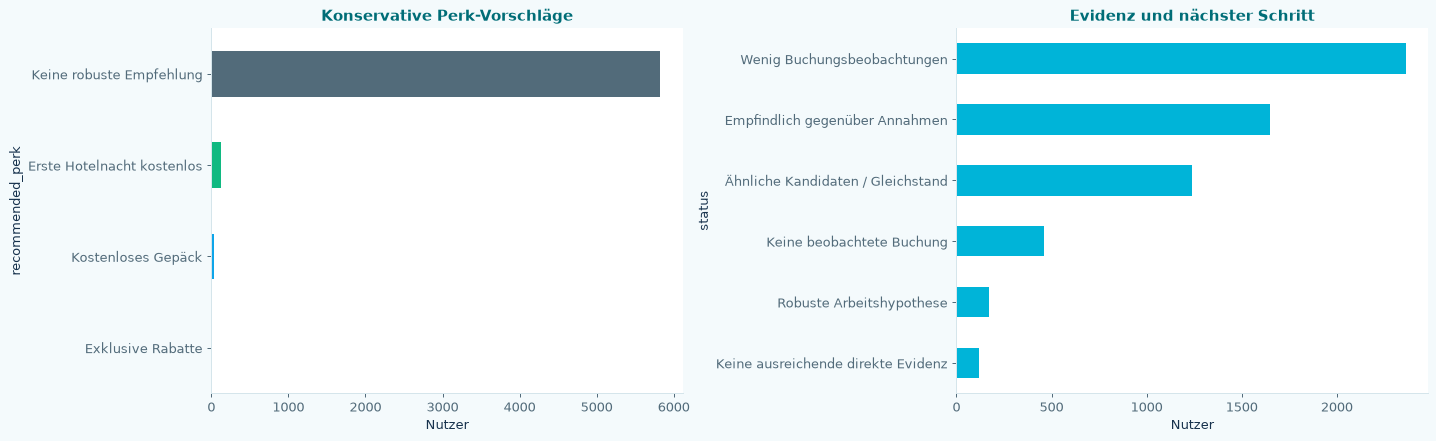

171 robuste Arbeitsvorschläge; 5,827 Nutzer erhalten einen Beobachtungs-/Testauftrag statt eines erzwungenen Perks. 401 Nutzer erfüllen nur den separaten Mahlzeiten-Testproxy.

In [ ]:
ranked_candidates=perk_scores.apply(lambda row: row.dropna().loc[lambda x:x.gt(0)].sort_values(ascending=False).head(2).index.tolist(),axis=1)
assignments=pd.DataFrame(index=user_features.index)
assignments["cluster_reference"]=cluster_labels
assignments["cluster_working"]=k_models[preferred_k].labels_
assignments["baseline_recommendation"]=accepted
assignments["rule_segment"]=rule_segments
assignments["recommended_perk"]=robust_recommendation
assignments["candidate_1"]=ranked_candidates.map(lambda x:x[0] if x else pd.NA)
assignments["candidate_2"]=ranked_candidates.map(lambda x:x[1] if len(x)>1 else pd.NA)
assignments["score_gap"]=perk_gap;assignments["tie"]=perk_ties
assignments["sensitivity_agreement"]=perk_stability_rate
assignments["status"]="Robuste Arbeitshypothese"
assignments["next_action"]="Vorgeschlagenen Perk gegen allgemeine Einladung testen"
uncertain=robust_recommendation.isna()
assignments.loc[uncertain,"status"]="Empfindlich gegenüber Annahmen"
assignments.loc[uncertain,"next_action"]="Regeln prüfen; vorläufig allgemeine Einladung"
ambiguous=uncertain&top_candidate.notna()&(perk_gap.lt(.1)|perk_ties)
assignments.loc[ambiguous,"status"]="Ähnliche Kandidaten / Gleichstand"
assignments.loc[ambiguous,"next_action"]="Kandidaten getrennt testen; keine automatische Auswahl"
no_candidate=uncertain&top_candidate.isna()
assignments.loc[no_candidate,"status"]="Keine ausreichende direkte Evidenz"
assignments.loc[no_candidate,"next_action"]="Datendeckung und Verhalten prüfen; allgemeine Einladung"
few=uncertain&user_features["booked_trip_count"].lt(3)
assignments.loc[few,"status"]="Wenig Buchungsbeobachtungen"
assignments.loc[few,"next_action"]="Weiter beobachten; allgemeine Einladung"
none=user_features["booked_trip_count"].eq(0)
assignments.loc[none,"status"]="Keine beobachtete Buchung"
assignments.loc[none,"next_action"]="Allgemeine Einladung; Buchungsverhalten beobachten"
assignments["meal_test_proxy"]=user_features["known_distance_flight_count"].ge(3)&user_features["long_haul_share"].ge(.5)
assignments["booked_trip_count"]=user_features["booked_trip_count"]
assignments=assignments.join(perk_evidence)
assert len(assignments)==len(user_features) and assignments.index.is_unique
assert assignments["status"].notna().all() and assignments["next_action"].notna().all()
assert assignments["recommended_perk"].ne("Kostenlose Mahlzeiten").fillna(True).all()
status_report=assignments["status"].value_counts().rename("Nutzer").to_frame()
status_report["Anteil (%)"]=status_report["Nutzer"]/len(assignments)*100
eda.display_table(status_report.round(2),title="Alle Nutzer: Empfehlung oder nächste Aktion",card_width=WIDTH)
eda.display_table(assignments.head(20),title="Nachvollziehbare Einzelfälle",card_width=WIDTH)
fig,axes=plt.subplots(1,2,figsize=(16,5))
theme_perk_counts = assignments["recommended_perk"].fillna("Keine robuste Empfehlung").value_counts().sort_values()
theme_perk_counts.plot.barh(ax=axes[0], color=[perk_plot_color(label) for label in theme_perk_counts.index])
axes[0].set(title="Konservative Perk-Vorschläge",xlabel="Nutzer")
status_report["Nutzer"].sort_values().plot.barh(ax=axes[1],color=THEME["secondary"])
axes[1].set(title="Evidenz und nächster Schritt",xlabel="Nutzer");finish_plot(fig)
show_note(f"{int(robust_recommendation.notna().sum()):,} robuste Arbeitsvorschläge; {int(uncertain.sum()):,} Nutzer erhalten einen Beobachtungs-/Testauftrag statt eines erzwungenen Perks. {int(assignments['meal_test_proxy'].sum()):,} Nutzer erfüllen nur den separaten Mahlzeiten-Testproxy.")

### 8.7. Ergebnis und Entscheidung zu Priorität 1-4
Die nachfolgenden Aussagen werden aus den aktuellen Tabellen berechnet. K-Means und
Regelgruppen bleiben getrennt; Perks werden ausschließlich anhand dokumentierter
Verhaltensindikatoren vorgeschlagen. Gewichtung und Mindestbeobachtungen können den
Vorschlag ändern. Es werden weder fünf bevorzugte Vorteile vorausgesetzt noch alle Nutzer
auf einen solchen verteilt. Die vollständige Übergabe besteht aus Vorschlägen **und**
Aktionen für unsichere Fälle. Weitere Themen und bestehende Zusatzanalysen bleiben unverändert.

In [ ]:
technical=k_comparison.set_index("k").loc[chosen_k]
show_note(f"Priorität 1: k={chosen_k} ist der technische Referenzpunkt (Silhouette {technical['Silhouette']:.3f}, größte Gruppe {technical['Größte Gruppe (%)']:.1f} %). Für Marketingzwecke zuerst die erklärbaren Regelgruppen verwenden; K-Means ergänzend interpretieren. Keine künstliche Festlegung auf k=5.")
show_note(f"Priorität 2: {rule_segments.nunique()} vollständige Regelgruppen; {int(rule_flags.sum(axis=1).gt(1).sum()):,} Nutzer erfüllen mehrere ausgeprägte Muster. Überschneidungen sind sichtbar statt durch die Reihenfolge der Regeln verdeckt.")
show_note("Priorität 3: pauschaler Hotel-Bonus entfernt, Ereigniszahlen berücksichtigt, Mahlzeiten aus automatischer Zuordnung entfernt und alle Gewichte variiert. Die Indikatoren bleiben zu testende Hypothesen.")
show_note(f"Priorität 4: {int(robust_recommendation.isna().sum()):,} Nutzer ohne robuste Empfehlung haben eine explizite nächste Aktion. Keine automatische Umwandlung dieser Fälle in Rabattkunden.")
working=k_comparison.set_index("k").loc[preferred_k]
show_note(f"Feinere explorative Arbeitslösung: k={preferred_k} (größte Gruppe {working['Größte Gruppe (%)']:.1f} %, minimale ARI {working['ARI Minimum']:.3f}). Auswahl: kleinstes k>=3 mit größter Gruppe <=80 % und ARI-Minimum >=0,8; falls keine Lösung geeignet ist, bleibt der technische Referenzpunkt. Diese Kriterien sind Arbeitsannahmen.")
for label,row in k_profiles[preferred_k].iterrows():
    show_note(f"Arbeitscluster {label}: Median {row['booked_trip_count']:.1f} gebuchte Reisen; Kombinationsanteil {row['both_booking_share']:.0%}; Hotelnächte {row['mean_hotel_nights']:.1f}; Flugvorlauf {row['mean_flight_lead_days']:.1f} Tage; beobachtete Stornoquote {row['observed_cancellation_rate']:.0%}. Jede Kennzahl nutzt nur bekannte Werte; Gruppen sind keine Personas mit bewiesener Präferenz.")
show_note(f"Strenge Robustheitsregel: {int(accepted.notna().sum()):,} eindeutige Basisvorschläge reduzieren sich auf {int(robust_recommendation.notna().sum()):,} Vorschläge, die alle Mindestzahl-, Abstand- und Gewichtsvarianten überstehen. Ein fehlender robuster Vorschlag beweist keinen fehlenden Bedarf.")
segment_folder=FEATURES_FOLDER/"priorities_1_4"
segment_folder.mkdir(parents=True,exist_ok=True)
exports_index={"user_decisions":assignments,"perk_scores":perk_scores,"perk_evidence":perk_evidence,"rule_profile":rule_profile,"rule_sizes":rule_sizes,"rule_flags":rule_flags,"cluster_matrix":cluster_matrix,"user_features_extended":user_features}
for name,table in exports_index.items():table.to_csv(segment_folder/f"{name}.csv",index=True)
for name,table in {"k_comparison":k_comparison,"cluster_stability":cluster_stability,"rule_stability":rule_stability,"rule_k_comparison":rule_k_comparison,"perk_sensitivity":perk_sensitivity,"status_report":status_report.reset_index(),"feature_selection":feature_selection,"outlier_report":outlier_report}.items():table.to_csv(segment_folder/f"{name}.csv",index=False)
for k in range(2,6):
    k_profiles[k].to_csv(segment_folder/f"cluster_profile_k{k}.csv")
    labels=pd.Series(k_models[k].labels_,index=user_features.index,name="cluster")
    user_features[list(candidate_reasons)].join(labels).groupby("cluster").count().to_csv(segment_folder/f"cluster_observations_k{k}.csv")
    rule_cluster_tables[k].to_csv(segment_folder/f"rules_vs_k{k}.csv")
    labels.to_csv(segment_folder/f"cluster_labels_k{k}.csv")
show_note(f"Ergebnisse zu Priorität 1-4 gespeichert: {segment_folder}")
pd.DataFrame([{ "Technischer Referenzpunkt k":chosen_k,"Explorative Arbeitslösung k":preferred_k,"Nutzer":len(assignments),"Basisvorschläge":int(accepted.notna().sum()),"Robuste Vorschläge":int(robust_recommendation.notna().sum()),"Ohne robuste Empfehlung":int(robust_recommendation.isna().sum()),"Kriterien Arbeitslösung":"kleinstes k>=3; größte Gruppe<=80%; minimale ARI>=0.8"}]).to_csv(segment_folder/"decision_log.csv",index=False)


Priorität 1: k=2 ist der technische Referenzpunkt (Silhouette 0.471, größte Gruppe 94.4 %). Für Marketingzwecke zuerst die erklärbaren Regelgruppen verwenden; K-Means ergänzend interpretieren. Keine künstliche Festlegung auf k=5.

Priorität 2: 7 vollständige Regelgruppen; 70 Nutzer erfüllen mehrere ausgeprägte Muster. Überschneidungen sind sichtbar statt durch die Reihenfolge der Regeln verdeckt.

Priorität 3: pauschaler Hotel-Bonus entfernt, Ereigniszahlen berücksichtigt, Mahlzeiten aus automatischer Zuordnung entfernt und alle Gewichte variiert. Die Indikatoren bleiben zu testende Hypothesen.

Priorität 4: 5,827 Nutzer ohne robuste Empfehlung haben eine explizite nächste Aktion. Keine automatische Umwandlung dieser Fälle in Rabattkunden.

Feinere explorative Arbeitslösung: k=3 (größte Gruppe 73.3 %, minimale ARI 0.919). Auswahl: kleinstes k>=3 mit größter Gruppe <=80 % und ARI-Minimum >=0,8; falls keine Lösung geeignet ist, bleibt der technische Referenzpunkt. Diese Kriterien sind Arbeitsannahmen.

Arbeitscluster 0: Median 2.0 gebuchte Reisen; Kombinationsanteil 67%; Hotelnächte 6.0; Flugvorlauf 168.5 Tage; beobachtete Stornoquote 50%. Jede Kennzahl nutzt nur bekannte Werte; Gruppen sind keine Personas mit bewiesener Präferenz.

Arbeitscluster 1: Median 1.0 gebuchte Reisen; Kombinationsanteil 0%; Hotelnächte 7.0; Flugvorlauf 7.5 Tage; beobachtete Stornoquote 0%. Jede Kennzahl nutzt nur bekannte Werte; Gruppen sind keine Personas mit bewiesener Präferenz.

Arbeitscluster 2: Median 3.0 gebuchte Reisen; Kombinationsanteil 100%; Hotelnächte 2.7; Flugvorlauf 7.6 Tage; beobachtete Stornoquote 0%. Jede Kennzahl nutzt nur bekannte Werte; Gruppen sind keine Personas mit bewiesener Präferenz.

Strenge Robustheitsregel: 1,931 eindeutige Basisvorschläge reduzieren sich auf 171 Vorschläge, die alle Mindestzahl-, Abstand- und Gewichtsvarianten überstehen. Ein fehlender robuster Vorschlag beweist keinen fehlenden Bedarf.

Ergebnisse zu Priorität 1-4 gespeichert: outputs\release_feature_test\working_cutoff_20230716\priorities_1_4

## 9. Verbindlicher Abschluss
Die Hauptanalyse endet am 16.07.2023. Die bisherige Baseline ist in `src/02_Features_Baseline.ipynb`
eingefroren; Notebook 04 zeigt den Stichtagsvergleich ohne Änderung der Nutzerkohorte.
Die endgültigen Gruppenbezeichnungen, Perk-/Aktionsdateien und der Testplan stehen in Notebook 05.
Ungefilterte Zeitverläufe und der Datenbruch werden ausschließlich in Notebook 03 behandelt.